# SUSTAIN — 3-Month and 6-Month Livelihood Market-Risk Prediction
**End-to-end workflow:** dataset inspection → EDA → audit of existing risk methods → cleaning → category indicators → feature engineering → future risk targets (`Risk_Label_3M`, `Risk_Label_6M`) → leakage checks → model training, time-aware validation and independent test → interpretation (permutation importance, SHAP) → saved, reloadable model artifacts → Excel export.

## Read this first — what the data can and cannot support
The workflow was rebuilt from the raw combined workbook. Inspection established facts that constrain every later step (all are re-computed and printed below):

* The main table (`Training_Table_HH_Month`) has **547 household-month rows; 448 are tagged synthetic in the source** and only **99 are real**.
* The 99 real rows **have no persistent household identifier** (household_key and NIC are empty; `_uuid` is unique per submission) and cover only **Jan–Mar 2026**. A real household can therefore **never be matched to its own observation 3 or 6 months later** — real 3M/6M targets cannot be constructed at all.
* The synthetic panel (58 households, Jan–Sep 2026) is the only data with repeated observations of the same household. The source documentation states the synthetic rows *"imitate the real rows"* and must *"not be used as evidence"*.
* The only existing **Low/Medium/High** columns are **category × month market tiers** (PPI/fuel pressure and volatility tiers), not household risk labels. No household-level Low/Medium/High label exists.

**Consequence.** The full pipeline is implemented and executed, but the 3M and 6M models are trained and tested on the synthetic panel only. Their metrics demonstrate that the pipeline works and is leakage-safe; they are **not evidence of real-world predictive performance**, and the saved models are flagged **NOT deployment-ready**. Every place where this matters is flagged in the notebook and in the `Limitations_Validation` sheet.

No research proposal or literature files were supplied with this run, so methodological choices are justified from the dataset, its embedded documentation, and standard ML practice; no external references are cited.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Project objectives and configuration

In [2]:
import os, sys, json, re, warnings, platform, hashlib, shutil, datetime as dt
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

# ---- configurable paths ----------------------------------------------------
DEFAULT_COLAB_INPUT = "/content/drive/MyDrive/NEW DATA/SUSTAIN_Model_Training_Combined_Dataset.xlsx"
DEFAULT_COLAB_OUTPUT = "/content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs"
INPUT_PATH = os.environ.get("SUSTAIN_INPUT", DEFAULT_COLAB_INPUT if IN_COLAB else "data/SUSTAIN_Model_Training_Combined_Dataset.xlsx")
OUTPUT_DIR = os.environ.get("SUSTAIN_OUTPUT", DEFAULT_COLAB_OUTPUT if IN_COLAB else "outputs")
RANDOM_STATE = 42
HORIZONS = {"3M": 3, "6M": 6}
CLASSES = ["Low", "Medium", "High"]          # ordinal order
CLASS_TO_INT = {c: i for i, c in enumerate(CLASSES)}
LABEL_METHOD_VERSION = "SUSTAIN-HH-Risk-Rule v1.0 (provisional, requires expert validation)"
print("Running in Colab:", IN_COLAB)
print("INPUT_PATH :", INPUT_PATH)
print("OUTPUT_DIR :", OUTPUT_DIR)

Running in Colab: True
INPUT_PATH : /content/drive/MyDrive/NEW DATA/SUSTAIN_Model_Training_Combined_Dataset.xlsx
OUTPUT_DIR : /content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs


## 2. Google Drive mounting and input-file verification
In Colab the drive is mounted automatically. Outside Colab set the environment variables `SUSTAIN_INPUT` / `SUSTAIN_OUTPUT`, or place the workbook at `data/`.

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # xgboost and shap are pre-installed in Colab; install if missing
    try:
        import xgboost, shap  # noqa
    except ImportError:
        !pip -q install xgboost shap

if not os.path.exists(INPUT_PATH):
    raise FileNotFoundError(f"STOP: input workbook not found at {INPUT_PATH}. Set SUSTAIN_INPUT or fix the path.")
os.makedirs(OUTPUT_DIR, exist_ok=True)
FIG_DIR = os.path.join(OUTPUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()

INPUT_SHA = sha256(INPUT_PATH)
# untouched copy of the original for traceability
ORIG_COPY = os.path.join(OUTPUT_DIR, "original_untouched_" + os.path.basename(INPUT_PATH))
if not os.path.exists(ORIG_COPY):
    shutil.copy2(INPUT_PATH, ORIG_COPY)
assert sha256(ORIG_COPY) == INPUT_SHA, "copy of original differs from source"
print("Input SHA-256:", INPUT_SHA)
print("Untouched copy:", ORIG_COPY)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Input SHA-256: 9732f43f0e7add79e696a169159473ab2c12b4f58eb7e7f5ff16522b409344f2
Untouched copy: /content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs/original_untouched_SUSTAIN_Model_Training_Combined_Dataset.xlsx


In [4]:
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
import sklearn, joblib
from scipy import stats
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
try:
    import xgboost as xgb; HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    import shap; HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

# chart styling: thin marks, recessive grid, fixed categorical order (validated reference palette)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
RISK_COLORS = {"Low": "#9cc3ee", "Medium": "#2a78d6", "High": "#0d3d7a"}   # one hue, light→dark (ordinal)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "lines.linewidth": 2, "axes.prop_cycle": matplotlib.cycler(color=SERIES),
                     "font.size": 9})
def savefig(name):
    p = os.path.join(FIG_DIR, name); plt.tight_layout(); plt.savefig(p, bbox_inches="tight"); plt.show(); return p

VERSIONS = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__ if HAS_XGB else "not installed",
            "shap": shap.__version__ if HAS_SHAP else "not installed", "joblib": joblib.__version__}
print(VERSIONS)

{'python': '3.13.16', 'pandas': '2.2.3', 'numpy': '2.1.3', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'shap': '0.54.1', 'joblib': '1.6.0'}


## 3. Load all relevant Excel worksheets
All sheets are read as-is. `raw` is never modified; all cleaning happens on a copy.

In [5]:
import openpyxl
sheets = pd.read_excel(INPUT_PATH, sheet_name=None)
MAIN = "Training_Table_HH_Month"
required_sheets = [MAIN, "Column_Dictionary"]
missing_sheets = [s for s in required_sheets if s not in sheets]
if missing_sheets:
    raise ValueError(f"STOP: required worksheet(s) missing: {missing_sheets}")
raw = sheets[MAIN].copy(deep=True)
RAW_FROZEN = raw.copy(deep=True)       # used later to prove raw values were not altered

# any Excel formulas embedded? (would document label logic)
wb_f = openpyxl.load_workbook(INPUT_PATH, data_only=False, read_only=True)
formula_counts = {}
for ws in wb_f.worksheets:
    n = 0
    for row in ws.iter_rows(values_only=True):
        n += sum(1 for v in row if isinstance(v, str) and v.startswith("="))
    formula_counts[ws.title] = n
wb_f.close()
sheet_summary = pd.DataFrame([{"Worksheet": k, "Rows": v.shape[0], "Columns": v.shape[1],
                               "Excel_formulas": formula_counts.get(k, 0)} for k, v in sheets.items()])
sheet_summary

,Worksheet,Rows,Columns,Excel_formulas
0,Training_Table_HH_Month,547,205,0
1,Category_Month_Table,140,56,0
2,Merge_Documentation,9,2,0
3,Column_Dictionary,205,2,0
4,Validation_Checks,13,4,0
5,Limitations,8,2,0
6,Participant_Context,3,6,0


In [6]:
for name in ["Merge_Documentation", "Validation_Checks", "Limitations", "Participant_Context"]:
    if name in sheets:
        print(f"===== {name}"); display(sheets[name])

===== Merge_Documentation


,Topic,Detail
0,Purpose,Starting table for a market-linked risk model: household...
1,Unit of the main table,"One row per household monitoring visit (547), all origin..."
2,Joins,Left join on Month (YYYY-MM) and Category_Key to the cat...
3,Market features,From the v2 notebook outputs: for each category its prim...
4,Targets,Derived 1/0/blank columns T_* from the monitoring answer...
5,Synthetic data,448 of 547 rows are tagged synthetic. They are kept and ...
6,Not included,"BRIGHT survey (different survey, 2023-2025, no shared ho..."
7,Not done,"No cleaning of source values, no imputation, no duplicat..."
8,Category_Month_Table,"The same data aggregated to Month x Category, separately..."


===== Validation_Checks


,Check,Flag,Result,Detail
0,Rows: monitoring source vs training table,OK,547 vs 547,NaN
1,All original monitoring cells unchanged (value comparison),OK,0 mismatches over 156 columns x 547 rows,NaN
2,No row duplication from joins,OK,"Left joins on unique (Category_Key, Month) / Month keys;...",NaN
3,Feature join coverage (rows with market features),INFO,"{'REAL (not tagged synthetic)': {'rows': 99, 'with_categ...",Category features exist only for 6 categories with 48-mo...
4,Rows without any category key,ISSUE,62,Blank in the source (question 3.1); not inferred
5,Rows by Row_Basis,INFO,"{'SYNTHETIC (tagged in source)': 448, 'REAL (not tagged ...","Synthetic rows kept and flagged, never removed"
6,Months covered by REAL rows,ISSUE,"{'2026-01': 1, '2026-02': 32, '2026-03': 66}",Too few months for a time-based split
7,Real rows with BOTH a market-stress target and category ...,ISSUE,11,Usable real training rows for a market-linked model
8,Category labels not in the 9-category list,ISSUE,"{'FISHERIES & AQUACULTURE': 1, 'MISCELLANEOUS': 1}",Left as in source
9,Categories with no rows at all,ISSUE,"['TRANSPORT & LOGISTICS', 'BEAUTY AND WELLNESS']",No outcome data for these


===== Limitations


,Limitation,Consequence
0,"Only 99 real monitoring rows, Feb-Mar 2026 (one in Jan)",A time-based hold-out is not possible; any reported accu...
1,Only a few real rows have category market features,"Categories without 48-month evidence (Trade, Other, etc...."
2,Transport & Logistics and Beauty & Wellness have no moni...,No outcomes for these categories
3,62 rows have no category,Cannot be linked to market features
4,Targets are yes/no or banded; many Don't know answers,"Weak, noisy target; blanks excluded from each target sep..."
5,Market features cover the same period as 9 months of out...,Little variation in 12-month price changes within 2026; ...
6,Synthetic rows resemble real ones,Including them would inflate scores without adding evidence
7,"Reference month of ""last month"" answers is unclear",Features at t and t-1 are both provided


===== Participant_Context


,District,Rows,Livelihood_filled,Grant_Disbursed_Yes,Grant_Disbursed_No,Grant_Disbursed_blank
0,Ampara,199,0,120,0,79
1,Badulla,239,237,89,17,133
2,Monaragala,221,126,121,1,99


**Interpretation.** The workbook contains no Excel formulas, so no label-generation logic is embedded in cells. The documentation sheets describe how the table was assembled (left joins of monitoring rows to category-month market features from an upstream "v2 notebook", which was *not* supplied) and how the derived `T_*` outcome columns were built. These statements are treated as claims to verify, not as facts.

## 4. Dataset structure and variable inspection

In [7]:
cd = sheets["Column_Dictionary"].set_index("Column")["Meaning"].to_dict()
def col_group(c):
    m = cd.get(c, "")
    if c.startswith("T_"): return "Derived outcome (T_*)"
    if c.startswith("Macro_"): return "Macro market feature"
    if c.startswith(("Primary_", "Category_")) and c not in ("Category_Key", "Category_Key_Note"): return "Category market feature"
    if m.startswith("Added"): return "Added identifier/key"
    if m.startswith("Original"): return "Original monitoring-form column"
    return "Undocumented"

def sample_vals(s, k=4):
    v = s.dropna().astype(str).unique()[:k]
    return " | ".join(x[:40] for x in v)

col_dict = pd.DataFrame({
    "Column": raw.columns,
    "Group": [col_group(c) for c in raw.columns],
    "Dtype": [str(raw[c].dtype) for c in raw.columns],
    "Non_null": [int(raw[c].notna().sum()) for c in raw.columns],
    "Missing_pct": [round(100 * raw[c].isna().mean(), 1) for c in raw.columns],
    "N_unique": [int(raw[c].nunique()) for c in raw.columns],
    "Sample_values": [sample_vals(raw[c]) for c in raw.columns],
    "Documented_meaning": [cd.get(c, "NOT IN Column_Dictionary") for c in raw.columns],
})
print("Columns:", raw.shape[1], "| undocumented:", (col_dict.Documented_meaning == "NOT IN Column_Dictionary").sum())
print(col_dict.Group.value_counts())
print("Fully empty columns:", (col_dict.Non_null == 0).sum())
col_dict.head(15)

Columns: 205 | undocumented: 0
Group
Original monitoring-form column    156
Category market feature             24
Macro market feature                12
Derived outcome (T_*)                8
Added identifier/key                 5
Name: count, dtype: int64
Fully empty columns: 60


,Column,Group,Dtype,Non_null,Missing_pct,N_unique,Sample_values,Documented_meaning
0,Source_Row,Added identifier/key,int64,547,0.0,547,2 | 3 | 4 | 5,Added: Excel row in the monitoring sheet (header=1)
1,Row_Basis,Added identifier/key,object,547,0.0,2,REAL (not tagged synthetic) | SYNTHETIC (tagged in source),Added: SYNTHETIC if _tags = synthetic or household_key s...
2,Month,Added identifier/key,object,547,0.0,9,2026-02 | 2026-03 | 2026-01 | 2026-04,Added: monitoring_period (YYYY-MM)
3,Category_Key,Added identifier/key,object,485,11.3,9,"OTHER | GARMENT TEXTILE, HANDICRAFTS | TRADE | LIVESTOCK...",Added: question 3.1 label; 4 variant spellings mapped to...
4,Category_Key_Note,Added identifier/key,object,547,0.0,3,as in source | blank in source - not mapped | variant la...,Added: how Category_Key was obtained
5,T_Business_Not_Running,Derived outcome (T_*),int64,547,0.0,2,0 | 1,Derived target: 1 if 3.3 = No
6,T_No_Profit_Last_Month,Derived outcome (T_*),float64,496,9.3,2,1.0 | 0.0,"Derived target: 1 if 3.8 = No, 0 if Yes, blank otherwise"
7,T_Not_Progressing_Well,Derived outcome (T_*),float64,544,0.5,2,1.0 | 0.0,Derived: 1 if coach says 3.9 = No
8,T_Revenue_Lowest_Band,Derived outcome (T_*),float64,342,37.5,2,0.0 | 1.0,"Derived: 1 if revenue band is LKR 0-10,000; ""Don't know""..."
9,T_Sales_Below_Expected,Derived outcome (T_*),float64,391,28.5,2,0.0 | 1.0,Derived: 3.10.1 Yes


In [8]:
IS_REAL = raw["Row_Basis"].astype(str).str.startswith("REAL")
IS_SYN = ~IS_REAL
print(raw["Row_Basis"].value_counts())
display(pd.crosstab(raw["Month"], raw["Row_Basis"], margins=True))
display(pd.crosstab(raw["Category_Key"].fillna("(blank)"), raw["Row_Basis"], margins=True))

Row_Basis
SYNTHETIC (tagged in source)    448
REAL (not tagged synthetic)      99
Name: count, dtype: int64


Row_Basis,REAL (not tagged synthetic),SYNTHETIC (tagged in source),All
Month,,,
2026-01,1,47,48
2026-02,32,48,80
2026-03,66,48,114
2026-04,0,50,50
2026-05,0,48,48
2026-06,0,46,46
2026-07,0,50,50
2026-08,0,54,54
2026-09,0,57,57


Row_Basis,REAL (not tagged synthetic),SYNTHETIC (tagged in source),All
Category_Key,,,
(blank),62,0,62
AGRICULTURE & PLANTATION CROPS,9,96,105
"CONSTRUCTION, BUILDING AND REPAIR",0,59,59
FISHERIES & AQUACULTURE,1,0,1
FOOD PROCESSING & PRODUCTION,1,54,55
"GARMENT TEXTILE, HANDICRAFTS",7,76,83
LIVESTOCK & ANIMAL HUSBANDRY,5,54,59
MISCELLANEOUS,1,0,1
OTHER,11,49,60


In [9]:
# identifiers: can the same household be followed over time?
id_cols = ["household_key", "_uuid", "meta/rootUuid", "_index", "1.7 Participant NIC Number",
           "1.8.1 Corrected NIC Number (if different)"]
id_check = pd.DataFrame([{"Column": c,
                          "Real_non_null": int(raw.loc[IS_REAL, c].notna().sum()),
                          "Real_unique": int(raw.loc[IS_REAL, c].nunique()),
                          "Synthetic_non_null": int(raw.loc[IS_SYN, c].notna().sum()),
                          "Synthetic_unique": int(raw.loc[IS_SYN, c].nunique())} for c in id_cols])
display(id_check)
# attempt a demographic linkage of real rows (district, DS, GND, gender, age)
link_keys = ["1.10. Participant District", "1.11. Participant Divisional Secretariat", "1.12. Participant GND",
             "1.6. Gender of the Empowerment Program Participant", "1.7. Age of the Empowerment Program Participant"]
rl = raw.loc[IS_REAL].dropna(subset=link_keys).groupby(link_keys)["Month"].nunique()
print(f"Real rows with complete demographic keys: {int(raw.loc[IS_REAL].dropna(subset=link_keys).shape[0])}; "
      f"distinct demographic profiles: {len(rl)}; profiles seen in >1 month: {int((rl > 1).sum())}")
hh = raw.loc[IS_SYN].groupby("household_key")["Month"].agg(["nunique", "min", "max"])
print("Synthetic households:", len(hh)); print(hh["nunique"].value_counts().sort_index().rename("households by #months observed"))

,Column,Real_non_null,Real_unique,Synthetic_non_null,Synthetic_unique
0,household_key,0,0,448,58
1,_uuid,99,99,448,448
2,meta/rootUuid,99,99,448,448
3,_index,99,99,448,448
4,1.7 Participant NIC Number,0,0,0,0
5,1.8.1 Corrected NIC Number (if different),0,0,0,0


Real rows with complete demographic keys: 28; distinct demographic profiles: 28; profiles seen in >1 month: 0
Synthetic households: 58
nunique
1     2
2     4
7     4
8    22
9    26
Name: households by #months observed, dtype: int64


**Interpretation.**
* Real rows: `household_key` and NIC fields are empty; `_uuid`/`rootUuid`/`_index` are unique per submission, so they identify a *form submission*, not a household. A demographic linkage attempt (district + DS + GND + gender + age) finds **no profile observed in more than one month**. Real rows therefore cannot be followed over time.
* Synthetic rows: 58 `SYN-HH-*` households, most observed in 8–9 of the 9 months (Jan–Sep 2026) — a genuine panel structure, but synthetic.
* Monitoring frequency is monthly (`monitoring_period` = YYYY-MM; checked against visit dates in Section 8). Horizons are therefore defined in calendar months, not in rows.

In [10]:
desc_num = raw.select_dtypes("number").describe().T
desc_num.head(30)

,count,mean,std,min,25%,50%,75%,max
Source_Row,547.0,275.000000,158.049570,2.000000,138.500000,275.000000,411.500000,548.000000
T_Business_Not_Running,547.0,0.062157,0.241662,0.000000,0.000000,0.000000,0.000000,1.000000
T_No_Profit_Last_Month,496.0,0.433468,0.496054,0.000000,0.000000,0.000000,1.000000,1.000000
T_Not_Progressing_Well,544.0,0.185662,0.389191,0.000000,0.000000,0.000000,0.000000,1.000000
T_Revenue_Lowest_Band,342.0,0.581871,0.493974,0.000000,0.000000,1.000000,1.000000,1.000000
T_Sales_Below_Expected,391.0,0.202046,0.402041,0.000000,0.000000,0.000000,0.000000,1.000000
T_High_Input_Cost,480.0,0.052083,0.222427,0.000000,0.000000,0.000000,0.000000,1.000000
T_Inputs_Unavailable,470.0,0.017021,0.129488,0.000000,0.000000,0.000000,0.000000,1.000000
T_Market_Stress_Any,377.0,0.244032,0.430082,0.000000,0.000000,0.000000,0.000000,1.000000
Primary_Pct_Change_12M_t,318.0,2.599029,8.954374,-16.523531,0.136411,4.300975,8.872902,17.267226


## 5. Existing risk-label column identification
Every column is scanned for Low/Medium/High-type values. For each hit we establish **what level it is defined at** (household vs category-month) by checking whether it is constant within (`Category_Key`, `Month`).

In [11]:
tier_vocab = {"low", "medium", "high", "insufficient evidence"}
hits = []
for c in raw.columns:
    vals = set(raw[c].dropna().astype(str).str.strip().str.lower().unique())
    if vals and vals <= tier_vocab and ({"low", "high"} & vals):
        g = raw.dropna(subset=[c]).groupby(["Category_Key", "Month"])[c].nunique()
        hits.append({"Column": c, "Values": sorted(raw[c].dropna().unique().tolist()),
                     "Non_null_rows": int(raw[c].notna().sum()),
                     "Constant_within_Category_x_Month": bool((g <= 1).all()),
                     "Level": "Category x Month (market)" if (g <= 1).all() else "Household"})
label_hits = pd.DataFrame(hits); display(label_hits)
name_hits = [c for c in raw.columns if re.search(r"risk|tier|pressure|volatil", c, re.I)]
print("Columns whose NAME suggests risk:", name_hits)
print("Columns literally named *Risk*:", [c for c in raw.columns if re.search("risk", c, re.I)])

,Column,Values,Non_null_rows,Constant_within_Category_x_Month,Level
0,Primary_Pressure_Tier_t,"[High, Low, Medium]",318,True,Category x Month (market)
1,Primary_Volatility_Tier_t,"[Low, Medium]",318,True,Category x Month (market)
2,Category_Pressure_Tier_t,"[High, Insufficient Evidence, Low, Medium]",426,True,Category x Month (market)
3,Category_Volatility_Tier_t,"[Insufficient Evidence, Low, Medium]",426,True,Category x Month (market)
4,Primary_Pressure_Tier_t_minus_1,"[High, Low, Medium]",361,True,Category x Month (market)
5,Primary_Volatility_Tier_t_minus_1,"[Low, Medium]",361,True,Category x Month (market)
6,Category_Pressure_Tier_t_minus_1,"[High, Insufficient Evidence, Low, Medium]",483,True,Category x Month (market)
7,Category_Volatility_Tier_t_minus_1,"[Insufficient Evidence, Low, Medium]",483,True,Category x Month (market)


Columns whose NAME suggests risk: ['Primary_Pressure_t', 'Primary_Volatility_t', 'Primary_Pressure_Tier_t', 'Primary_Volatility_Tier_t', 'Category_Pressure_Tier_t', 'Category_Volatility_Tier_t', 'Category_Pressure_Tier_Ord_t', 'Category_Volatility_Tier_Ord_t', 'Primary_Pressure_t_minus_1', 'Primary_Volatility_t_minus_1', 'Primary_Pressure_Tier_t_minus_1', 'Primary_Volatility_Tier_t_minus_1', 'Category_Pressure_Tier_t_minus_1', 'Category_Volatility_Tier_t_minus_1', 'Category_Pressure_Tier_Ord_t_minus_1', 'Category_Volatility_Tier_Ord_t_minus_1']
Columns literally named *Risk*: []


**Finding.** No column named "Risk" exists and **no household-level Low/Medium/High label exists**. All Low/Medium/High columns are constant within category × month, i.e. they are **market tiers** describing the category's price environment in month *t* (or *t−1*), copied onto every household row of that category and month. They describe current/past market conditions, not future household risk.

The household-level risk-related information consists of the derived binary outcome columns `T_*`. We now verify (a) the `T_*` rules against the raw answers and (b) as much of the market-tier logic as the data allows.

In [12]:
def norm_ans(s):
    return s.astype(str).str.strip().str.replace("’", "'", regex=False).where(s.notna())

T_RULES = {  # target column: (source column, value->1, value->0); anything else -> blank
    "T_Business_Not_Running": ("3.3. Is the business running?", ["No"], ["Yes"]),
    "T_No_Profit_Last_Month": ("3.8. In the last month, did you make a profit from the livelihood?", ["No"], ["Yes"]),
    "T_Not_Progressing_Well": ("3.9. [FOR COACH ONLY] Is the participant progressing well in his/her livelihood?", ["No"], ["Yes"]),
    "T_Revenue_Lowest_Band": ("3.7. In the last month, how much total revenue/sales did you make from the livelihood?",
                              ["LKR 0 – 10,000"], ["LKR 10,001 – 20,000", "LKR 20,001 – 30,000", "More than 30,000"]),
    "T_Sales_Below_Expected": ("3.10.1. Sales less than expected", ["Yes"], ["No"]),
    "T_High_Input_Cost": ("3.10.3. High cost of inputs/materials", ["Yes"], ["No"]),
    "T_Inputs_Unavailable": ("3.10.4. Unavailability of inputs/materials", ["Yes"], ["No"]),
}
def rebuild_T(df):
    out = pd.DataFrame(index=df.index)
    for t, (src, one, zero) in T_RULES.items():
        a = norm_ans(df[src]); out[t] = np.where(a.isin(one), 1.0, np.where(a.isin(zero), 0.0, np.nan))
    parts = out[["T_Sales_Below_Expected", "T_High_Input_Cost", "T_Inputs_Unavailable"]]
    out["T_Market_Stress_Any"] = np.where((parts == 1).any(axis=1), 1.0, np.where((parts == 0).all(axis=1), 0.0, np.nan))
    return out
Tchk = rebuild_T(raw)
t_verify = []
for t in Tchk.columns:
    a, b = raw[t], Tchk[t]
    mism = int(((a != b) & ~(a.isna() & b.isna())).sum())
    t_verify.append({"Column": t, "Source": T_RULES.get(t, ("3.10.1/3.10.3/3.10.4 combined",))[0],
                     "Mismatches_after_rebuild": mism, "Rate_1": round(raw[t].mean(), 3),
                     "Blank_pct": round(100 * raw[t].isna().mean(), 1),
                     "Status": "VERIFIED (exact rebuild)" if mism == 0 else "NOT VERIFIED"})
t_verify = pd.DataFrame(t_verify); t_verify

,Column,Source,Mismatches_after_rebuild,Rate_1,Blank_pct,Status
0,T_Business_Not_Running,3.3. Is the business running?,0,0.062,0.0,VERIFIED (exact rebuild)
1,T_No_Profit_Last_Month,"3.8. In the last month, did you make a profit from the l...",0,0.433,9.3,VERIFIED (exact rebuild)
2,T_Not_Progressing_Well,3.9. [FOR COACH ONLY] Is the participant progressing wel...,0,0.186,0.5,VERIFIED (exact rebuild)
3,T_Revenue_Lowest_Band,"3.7. In the last month, how much total revenue/sales did...",0,0.582,37.5,VERIFIED (exact rebuild)
4,T_Sales_Below_Expected,3.10.1. Sales less than expected,0,0.202,28.5,VERIFIED (exact rebuild)
5,T_High_Input_Cost,3.10.3. High cost of inputs/materials,0,0.052,12.2,VERIFIED (exact rebuild)
6,T_Inputs_Unavailable,3.10.4. Unavailability of inputs/materials,0,0.017,14.1,VERIFIED (exact rebuild)
7,T_Market_Stress_Any,3.10.1/3.10.3/3.10.4 combined,0,0.244,31.1,VERIFIED (exact rebuild)


## 6. Existing category-specific risk-methodology audit
The market tiers come from an upstream notebook ("v2") that was not supplied. We reconstruct what can be verified from the data itself: the adverse-direction rule linking `Primary_Pressure` to `Primary_Pct_Change_12M`, the tier thresholds implied by observed values, the ordinal encoding, and whether the category tier equals the primary-indicator tier.

In [13]:
cm = sheets["Category_Month_Table"]
def long_market(cm):
    base = ["Primary_Indicator", "Primary_Pct_Change_12M", "Primary_Pressure", "Primary_Volatility",
            "Primary_Pressure_Tier", "Primary_Volatility_Tier", "Category_Pressure_Tier", "Category_Volatility_Tier",
            "Category_Pressure_Tier_Ord", "Category_Volatility_Tier_Ord", "Category_Evidence_Grade", "Category_N_Evidence_Lines"]
    a = cm[["Month", "Category_Key"] + [b + "_t" for b in base]].copy(); a.columns = ["Month", "Category_Key"] + base
    b_ = cm[["Month", "Category_Key"] + [b + "_t_minus_1" for b in base]].copy(); b_.columns = ["Month", "Category_Key"] + base
    b_["Month"] = (pd.PeriodIndex(b_["Month"], freq="M") - 1).astype(str)
    m = pd.concat([a, b_]).drop_duplicates(["Month", "Category_Key"]).sort_values(["Category_Key", "Month"])
    return m
mkt = long_market(cm)
mkt_obs = mkt.dropna(subset=["Primary_Pressure"])
print("Category-months with primary-indicator evidence:", len(mkt_obs), "| categories:", mkt_obs.Category_Key.nunique(),
      "| months:", mkt_obs.Month.min(), "→", mkt_obs.Month.max())

# adverse-direction rule: Pressure = sign * Pct_change_12M
dir_rows = []
for cat, g in mkt_obs.groupby("Category_Key"):
    ratio = (g["Primary_Pressure"] / g["Primary_Pct_Change_12M"]).round(6)
    sign = ratio.unique()
    dir_rows.append({"Category_Key": cat, "Primary_Indicator": g["Primary_Indicator"].iloc[0],
                     "Pressure_equals": ("+1 x pct change (price RISE adverse: input cost)" if list(sign) == [1.0]
                                         else "-1 x pct change (price FALL adverse: output/selling price)" if list(sign) == [-1.0]
                                         else f"inconsistent {sign}"),
                     "Direction_verified": len(sign) == 1})
direction = pd.DataFrame(dir_rows); display(direction)

# implied thresholds: value ranges per tier per category
thr = (mkt_obs.groupby(["Category_Key", "Primary_Pressure_Tier"])["Primary_Pressure"].agg(["min", "max", "count"]).round(2))
display(thr)
vthr = (mkt_obs.groupby(["Category_Key", "Primary_Volatility_Tier"])["Primary_Volatility"].agg(["min", "max", "count"]).round(2))
display(vthr)
ord_ok = mkt.dropna(subset=["Category_Pressure_Tier_Ord"]).groupby("Category_Pressure_Tier")["Category_Pressure_Tier_Ord"].unique()
print("Ordinal encoding of Category_Pressure_Tier:", ord_ok.to_dict())
agree = mkt_obs.assign(same=mkt_obs.Primary_Pressure_Tier == mkt_obs.Category_Pressure_Tier)
print("Category tier == primary tier:", f"{agree.same.mean():.0%}", "of", len(agree), "category-months")
display(agree.loc[~agree.same, ["Category_Key", "Month", "Primary_Pressure", "Primary_Pressure_Tier", "Category_Pressure_Tier"]])

Category-months with primary-indicator evidence: 45 | categories: 5 | months: 2025-12 → 2026-08


,Category_Key,Primary_Indicator,Pressure_equals,Direction_verified
0,AGRICULTURE & PLANTATION CROPS,PPI A: Agriculture,-1 x pct change (price FALL adverse: output/selling price),True
1,"CONSTRUCTION, BUILDING AND REPAIR",PPI 23 Non-metallic minerals (cement/glass/bricks),+1 x pct change (price RISE adverse: input cost),True
2,FOOD PROCESSING & PRODUCTION,PPI 10 Manufacture of food products,-1 x pct change (price FALL adverse: output/selling price),True
3,"GARMENT TEXTILE, HANDICRAFTS",PPI 14 Manufacture of wearing apparel,-1 x pct change (price FALL adverse: output/selling price),True
4,LIVESTOCK & ANIMAL HUSBANDRY,PPI 014 Animal production,-1 x pct change (price FALL adverse: output/selling price),True


min    max  count
Category_Key                      Primary_Pressure_Tier                     
AGRICULTURE & PLANTATION CROPS    High                    9.47  16.52      5
                                  Low                    -5.79   1.10      4
CONSTRUCTION, BUILDING AND REPAIR Low                     0.78   4.83      5
                                  Medium                 11.98  14.89      4
FOOD PROCESSING & PRODUCTION      Low                    -6.26  -1.31      9
GARMENT TEXTILE, HANDICRAFTS      Low                   -10.32  -2.65      9
LIVESTOCK & ANIMAL HUSBANDRY      Low                   -17.27  -0.72      8
                                  Medium                  3.56   3.56      1

min   max  count
Category_Key                      Primary_Volatility_Tier                   
AGRICULTURE & PLANTATION CROPS    Low                      4.95  5.64      7
                                  Medium                   6.19  6.32      2
CONSTRUCTION, BUILDING AND REPAIR Low                      0.86  2.41      9
FOOD PROCESSING & PRODUCTION      Low                      0.45  1.52      9
GARMENT TEXTILE, HANDICRAFTS      Low                      1.05  2.20      9
LIVESTOCK & ANIMAL HUSBANDRY      Low                      6.33  7.27      9

Ordinal encoding of Category_Pressure_Tier: {'High': array([2.]), 'Low': array([0.]), 'Medium': array([1.])}
Category tier == primary tier: 84% of 45 category-months


,Category_Key,Month,Primary_Pressure,Primary_Pressure_Tier,Category_Pressure_Tier
0,AGRICULTURE & PLANTATION CROPS,2026-01,1.100152,Low,High
54,AGRICULTURE & PLANTATION CROPS,2026-07,-0.136411,Low,High
61,AGRICULTURE & PLANTATION CROPS,2026-08,-2.618392,Low,High
15,"GARMENT TEXTILE, HANDICRAFTS",2025-12,-7.801418,Low,High
15,"GARMENT TEXTILE, HANDICRAFTS",2026-01,-9.101796,Low,High
2,"GARMENT TEXTILE, HANDICRAFTS",2026-02,-8.872902,Low,High
36,"GARMENT TEXTILE, HANDICRAFTS",2026-04,-2.648354,Low,Medium


In [14]:
# Are the thresholds the same across categories? test: a value classed Low in one category but Medium/High in another
cross = []
for c1, g1 in mkt_obs.groupby("Category_Key"):
    for c2, g2 in mkt_obs.groupby("Category_Key"):
        lo1 = g1.loc[g1.Primary_Pressure_Tier == "Low", "Primary_Pressure"].max()
        hi2 = g2.loc[g2.Primary_Pressure_Tier != "Low", "Primary_Pressure"].min()
        if pd.notna(lo1) and pd.notna(hi2) and lo1 > hi2:
            cross.append((c1, round(lo1, 2), c2, round(hi2, 2)))
print("Evidence of category-specific thresholds (Low max in A > non-Low min in B):")
for x in cross: print("  ", x)

Evidence of category-specific thresholds (Low max in A > non-Low min in B):
   ('CONSTRUCTION, BUILDING AND REPAIR', 4.83, 'LIVESTOCK & ANIMAL HUSBANDRY', 3.56)


**Audit findings (existing market-risk method).**
1. **Adverse direction — verified.** For every category with evidence, `Primary_Pressure` is exactly ±1 × the 12-month % change of its primary PPI line: price *rises* are adverse for Construction (cement/brick/glass PPI = an input cost), price *falls* are adverse for Agriculture, Livestock, Food processing and Garment (output/selling-price PPIs). This is economically coherent and is **preserved**.
2. **Thresholds — partially verified.** Tiers are monotone in pressure within each category, but cut-offs are **category-specific** (e.g. pressure 3.56 is Medium for Livestock while 4.83 is Low for Construction), consistent with thresholds derived from each category's own 48-month history. The exact cut-offs and the volatility formula cannot be recovered without the v2 notebook.
3. **Category tier ≠ primary tier** in several category-months although only one evidence line exists — the aggregation rule is **unknown**.
4. **Coverage.** Market evidence exists for 5 data categories only (Agriculture, Livestock, Food processing, Garment/Handicrafts, Construction); Trade and Other are "Insufficient Evidence"; Transport & Logistics and Beauty & Wellness have no rows; no market data after 2026-08.
5. **Timing.** Tiers describe the market in month *t* (and *t−1*). They are **current-period market labels**, not household risk and not future risk.

**Existing household outcome method — verified.** The eight `T_*` columns are rebuilt exactly from the raw answers (0 mismatches). "Don't know" and blanks are kept as missing, which is preserved.

**Decision.** There is no existing household-level Low/Medium/High label to carry forward. The future targets are therefore built with a **new, transparent household rule** that is composed only of the verified `T_*` indicators (Section 13); the verified market method is **preserved unchanged** and used (a) as prediction-time features and (b) as an auxiliary market-tier persistence analysis.

In [15]:
existing_method_rows = []
for _, r in direction.iterrows():
    cat = r.Category_Key; g = mkt_obs[mkt_obs.Category_Key == cat]
    tiers = thr.loc[cat] if cat in thr.index.get_level_values(0) else None
    existing_method_rows.append({
        "Category_Key": cat, "Level": "Category x Month", "Existing_label_columns": "Primary_Pressure_Tier_t, Category_Pressure_Tier_t (+ _t_minus_1)",
        "Existing_score_columns": "Primary_Pressure_t, Primary_Volatility_t", "Source_indicator": r.Primary_Indicator,
        "Adverse_direction_rule": r.Pressure_equals, "Direction_status": "Verified from data" if r.Direction_verified else "Inconsistent",
        "Observed_tier_ranges": "; ".join(f"{t}: {row['min']}..{row['max']} (n={int(row['count'])})" for t, row in tiers.iterrows()) if tiers is not None else "",
        "Threshold_status": "Partially verified (category-specific; exact cut-offs not recoverable without v2 notebook)",
        "Category_tier_rule": f"Unknown (agrees with primary tier in {(g.Primary_Pressure_Tier == g.Category_Pressure_Tier).mean():.0%} of months)",
        "Label_timing": "Current market month t (and t-1)", "Evidence_source": "Category_Month_Table / Training_Table columns; Merge_Documentation; Column_Dictionary",
        "Months_with_evidence": f"{g.Month.min()}..{g.Month.max()} ({len(g)})"})
for cat in ["TRADE", "OTHER"]:
    existing_method_rows.append({"Category_Key": cat, "Level": "Category x Month", "Existing_label_columns": "Category_Pressure_Tier_t = 'Insufficient Evidence'",
        "Existing_score_columns": "none", "Source_indicator": "none (no 48-month evidence line)", "Adverse_direction_rule": "n/a",
        "Direction_status": "n/a", "Observed_tier_ranges": "", "Threshold_status": "n/a", "Category_tier_rule": "Insufficient Evidence",
        "Label_timing": "Current month", "Evidence_source": "Category_Month_Table", "Months_with_evidence": "none"})
existing_method_rows.append({"Category_Key": "ALL (household level)", "Level": "Household x Month",
    "Existing_label_columns": "none (no Low/Medium/High household label)", "Existing_score_columns": "none",
    "Source_indicator": "T_* binary outcomes from form questions 3.3, 3.7, 3.8, 3.9, 3.10.1, 3.10.3, 3.10.4",
    "Adverse_direction_rule": "1 = adverse answer", "Direction_status": "Verified (exact rebuild, 0 mismatches)",
    "Observed_tier_ranges": "", "Threshold_status": "n/a (binary)", "Category_tier_rule": "n/a",
    "Label_timing": "Current visit (refers to 'last month')", "Evidence_source": "Column_Dictionary + rebuild from raw answers",
    "Months_with_evidence": "2026-01..2026-09"})
Existing_Risk_Method = pd.DataFrame(existing_method_rows)
Existing_Risk_Method

,Category_Key,Level,Existing_label_columns,Existing_score_columns,Source_indicator,Adverse_direction_rule,Direction_status,Observed_tier_ranges,Threshold_status,Category_tier_rule,Label_timing,Evidence_source,Months_with_evidence
0,AGRICULTURE & PLANTATION CROPS,Category x Month,"Primary_Pressure_Tier_t, Category_Pressure_Tier_t (+ _t_...","Primary_Pressure_t, Primary_Volatility_t",PPI A: Agriculture,-1 x pct change (price FALL adverse: output/selling price),Verified from data,High: 9.47..16.52 (n=5); Low: -5.79..1.1 (n=4),Partially verified (category-specific; exact cut-offs no...,Unknown (agrees with primary tier in 67% of months),Current market month t (and t-1),Category_Month_Table / Training_Table columns; Merge_Doc...,2025-12..2026-08 (9)
1,"CONSTRUCTION, BUILDING AND REPAIR",Category x Month,"Primary_Pressure_Tier_t, Category_Pressure_Tier_t (+ _t_...","Primary_Pressure_t, Primary_Volatility_t",PPI 23 Non-metallic minerals (cement/glass/bricks),+1 x pct change (price RISE adverse: input cost),Verified from data,Low: 0.78..4.83 (n=5); Medium: 11.98..14.89 (n=4),Partially verified (category-specific; exact cut-offs no...,Unknown (agrees with primary tier in 100% of months),Current market month t (and t-1),Category_Month_Table / Training_Table columns; Merge_Doc...,2025-12..2026-08 (9)
2,FOOD PROCESSING & PRODUCTION,Category x Month,"Primary_Pressure_Tier_t, Category_Pressure_Tier_t (+ _t_...","Primary_Pressure_t, Primary_Volatility_t",PPI 10 Manufacture of food products,-1 x pct change (price FALL adverse: output/selling price),Verified from data,Low: -6.26..-1.31 (n=9),Partially verified (category-specific; exact cut-offs no...,Unknown (agrees with primary tier in 100% of months),Current market month t (and t-1),Category_Month_Table / Training_Table columns; Merge_Doc...,2025-12..2026-08 (9)
3,"GARMENT TEXTILE, HANDICRAFTS",Category x Month,"Primary_Pressure_Tier_t, Category_Pressure_Tier_t (+ _t_...","Primary_Pressure_t, Primary_Volatility_t",PPI 14 Manufacture of wearing apparel,-1 x pct change (price FALL adverse: output/selling price),Verified from data,Low: -10.32..-2.65 (n=9),Partially verified (category-specific; exact cut-offs no...,Unknown (agrees with primary tier in 56% of months),Current market month t (and t-1),Category_Month_Table / Training_Table columns; Merge_Doc...,2025-12..2026-08 (9)
4,LIVESTOCK & ANIMAL HUSBANDRY,Category x Month,"Primary_Pressure_Tier_t, Category_Pressure_Tier_t (+ _t_...","Primary_Pressure_t, Primary_Volatility_t",PPI 014 Animal production,-1 x pct change (price FALL adverse: output/selling price),Verified from data,Low: -17.27..-0.72 (n=8); Medium: 3.56..3.56 (n=1),Partially verified (category-specific; exact cut-offs no...,Unknown (agrees with primary tier in 100% of months),Current market month t (and t-1),Category_Month_Table / Training_Table columns; Merge_Doc...,2025-12..2026-08 (9)
5,TRADE,Category x Month,Category_Pressure_Tier_t = 'Insufficient Evidence',none,none (no 48-month evidence line),n/a,n/a,,n/a,Insufficient Evidence,Current month,Category_Month_Table,none
6,OTHER,Category x Month,Category_Pressure_Tier_t = 'Insufficient Evidence',none,none (no 48-month evidence line),n/a,n/a,,n/a,Insufficient Evidence,Current month,Category_Month_Table,none
7,ALL (household level),Household x Month,none (no Low/Medium/High household label),none,"T_* binary outcomes from form questions 3.3, 3.7, 3.8, 3...",1 = adverse answer,"Verified (exact rebuild, 0 mismatches)",,n/a (binary),n/a,Current visit (refers to 'last month'),Column_Dictionary + rebuild from raw answers,2026-01..2026-09


In [16]:
# Risk-label source register: one row per programme category
PROG_CATS = ["Agriculture & Plantation Crops", "Livestock & Animal Husbandry", "Food Processing & Production", "Trade",
             "Garment & Textile", "Handicrafts", "Construction, Building & Repair", "Transport & Logistics",
             "Beauty & Wellness", "Other"]
KEY_TO_PROG = {"AGRICULTURE & PLANTATION CROPS": "Agriculture & Plantation Crops",
               "LIVESTOCK & ANIMAL HUSBANDRY": "Livestock & Animal Husbandry",
               "FOOD PROCESSING & PRODUCTION": "Food Processing & Production", "TRADE": "Trade",
               "GARMENT TEXTILE, HANDICRAFTS": "Garment & Textile / Handicrafts (combined in source)",
               "CONSTRUCTION, BUILDING AND REPAIR": "Construction, Building & Repair", "OTHER": "Other",
               "FISHERIES & AQUACULTURE": "Other", "MISCELLANEOUS": "Other"}
PROG_TO_KEYS = {}
for k, v in KEY_TO_PROG.items(): PROG_TO_KEYS.setdefault(v, []).append(k)
def keys_for(pc):
    if pc in ("Garment & Textile", "Handicrafts"): return ["GARMENT TEXTILE, HANDICRAFTS"]
    return PROG_TO_KEYS.get(pc, [])

map_rows = []
for pc in PROG_CATS:
    ks = keys_for(pc); sub = raw[raw.Category_Key.isin(ks)]
    em = Existing_Risk_Method[Existing_Risk_Method.Category_Key.isin(ks)]
    has_mkt = len(em) and em.Source_indicator.iloc[0] not in ("none (no 48-month evidence line)",)
    n_real, n_syn = int((sub.Row_Basis.str.startswith("REAL")).sum()), int((~sub.Row_Basis.str.startswith("REAL")).sum())
    if not ks or len(sub) == 0:
        lim, act = "No monitoring rows and no market indicator in the dataset", "Develop new method when data exist (cannot be done now)"
    elif has_mkt:
        lim, act = "Market tier is category-month level, current period; thresholds not fully recoverable", "Preserve market tier as feature; validate thresholds with v2 notebook/experts"
    else:
        lim, act = "No market evidence line ('Insufficient Evidence')", "Household rule only; source a relevant price series (expert input)"
    if pc in ("Garment & Textile", "Handicrafts"):
        lim += "; Garment & Textile and Handicrafts are a single combined key in the source"
    map_rows.append({"Livelihood_category": pc, "Source_Category_Key(s)": ", ".join(ks) or "none",
                     "Rows_real": n_real, "Rows_synthetic": n_syn,
                     "Existing_risk_label_column": "Primary_Pressure_Tier_t / Category_Pressure_Tier_t (market tier)" if has_mkt else ("Category_Pressure_Tier_t = Insufficient Evidence" if len(sub) else "none"),
                     "Existing_risk_score_column": "Primary_Pressure_t, Primary_Volatility_t" if has_mkt else "none",
                     "Source_indicator_columns": (em.Source_indicator.iloc[0] + " (12-month % change)") if has_mkt else "none",
                     "Existing_rule": em.Adverse_direction_rule.iloc[0] + "; category-specific tier cut-offs" if has_mkt else "n/a",
                     "Household_label": "none existing; new rule from verified T_* indicators" if len(sub) else "none",
                     "Label_timing": "current month t" if len(sub) else "n/a",
                     "Evidence_source": "Category_Month_Table, Column_Dictionary, Merge_Documentation",
                     "Verification_status": "Direction verified; thresholds partially verified" if has_mkt else ("n/a" if not len(sub) else "Unknown (no market method)"),
                     "Limitations": lim, "Recommended_action": act})
Risk_Label_Column_Map = pd.DataFrame(map_rows); Risk_Label_Column_Map

,Livelihood_category,Source_Category_Key(s),Rows_real,Rows_synthetic,Existing_risk_label_column,Existing_risk_score_column,Source_indicator_columns,Existing_rule,Household_label,Label_timing,Evidence_source,Verification_status,Limitations,Recommended_action
0,Agriculture & Plantation Crops,AGRICULTURE & PLANTATION CROPS,9,96,Primary_Pressure_Tier_t / Category_Pressure_Tier_t (mark...,"Primary_Pressure_t, Primary_Volatility_t",PPI A: Agriculture (12-month % change),-1 x pct change (price FALL adverse: output/selling pric...,none existing; new rule from verified T_* indicators,current month t,"Category_Month_Table, Column_Dictionary, Merge_Documenta...",Direction verified; thresholds partially verified,"Market tier is category-month level, current period; thr...",Preserve market tier as feature; validate thresholds wit...
1,Livestock & Animal Husbandry,LIVESTOCK & ANIMAL HUSBANDRY,5,54,Primary_Pressure_Tier_t / Category_Pressure_Tier_t (mark...,"Primary_Pressure_t, Primary_Volatility_t",PPI 014 Animal production (12-month % change),-1 x pct change (price FALL adverse: output/selling pric...,none existing; new rule from verified T_* indicators,current month t,"Category_Month_Table, Column_Dictionary, Merge_Documenta...",Direction verified; thresholds partially verified,"Market tier is category-month level, current period; thr...",Preserve market tier as feature; validate thresholds wit...
2,Food Processing & Production,FOOD PROCESSING & PRODUCTION,1,54,Primary_Pressure_Tier_t / Category_Pressure_Tier_t (mark...,"Primary_Pressure_t, Primary_Volatility_t",PPI 10 Manufacture of food products (12-month % change),-1 x pct change (price FALL adverse: output/selling pric...,none existing; new rule from verified T_* indicators,current month t,"Category_Month_Table, Column_Dictionary, Merge_Documenta...",Direction verified; thresholds partially verified,"Market tier is category-month level, current period; thr...",Preserve market tier as feature; validate thresholds wit...
3,Trade,TRADE,2,60,Category_Pressure_Tier_t = Insufficient Evidence,none,none,n/a,none existing; new rule from verified T_* indicators,current month t,"Category_Month_Table, Column_Dictionary, Merge_Documenta...",Unknown (no market method),No market evidence line ('Insufficient Evidence'),Household rule only; source a relevant price series (exp...
4,Garment & Textile,"GARMENT TEXTILE, HANDICRAFTS",7,76,Primary_Pressure_Tier_t / Category_Pressure_Tier_t (mark...,"Primary_Pressure_t, Primary_Volatility_t",PPI 14 Manufacture of wearing apparel (12-month % change),-1 x pct change (price FALL adverse: output/selling pric...,none existing; new rule from verified T_* indicators,current month t,"Category_Month_Table, Column_Dictionary, Merge_Documenta...",Direction verified; thresholds partially verified,"Market tier is category-month level, current period; thr...",Preserve market tier as feature; validate thresholds wit...
5,Handicrafts,"GARMENT TEXTILE, HANDICRAFTS",7,76,Primary_Pressure_Tier_t / Category_Pressure_Tier_t (mark...,"Primary_Pressure_t, Primary_Volatility_t",PPI 14 Manufacture of wearing apparel (12-month % change),-1 x pct change (price FALL adverse: output/selling pric...,none existing; new rule from verified T_* indicators,current month t,"Category_Month_Table, Column_Dictionary, Merge_Documenta...",Direction verified; thresholds partially verified,"Market tier is category-month level, current period; thr...",Preserve market tier as feature; validate thresholds wit...
6,"Construction, Building & Repair","CONSTRUCTION, BUILDING AND REPAIR",0,59,Primary_Pressure_Tier_t / Category_Pressure_Tier_t (mark...,"Primary_Pressure_t, Primary_Volatility_t",PPI 23 Non-metallic minerals (cement/glass/bricks) (12-m...,+1 x pct change (price RISE adverse: input cost); catego...,none existing; new rule from verified T_* indicators,current month t,"Category_Month_Table, Column_Dictionary, Merge_Documenta...",Direction verified; thresholds partially verified,"Market tier is cat

## 7. Exploratory data analysis

Columns 100% empty: 60 | >50% missing: 103 | fully complete: 44
Group
Added identifier/key                2.3
Category market feature            30.9
Derived outcome (T_*)              16.6
Macro market feature                0.0
Original monitoring-form column    61.8
Name: Missing_pct, dtype: float64


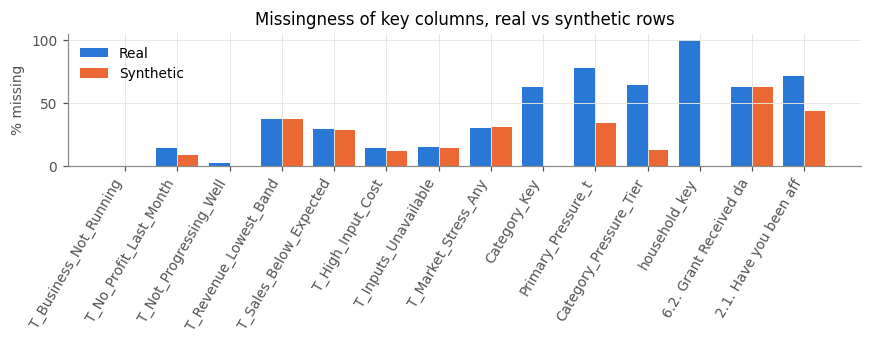

'/content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs/figures/eda_missingness.png'

In [17]:
miss = raw.isna().mean().sort_values(ascending=False)
print(f"Columns 100% empty: {(miss == 1).sum()} | >50% missing: {(miss > .5).sum()} | fully complete: {(miss == 0).sum()}")
grp_miss = col_dict.groupby("Group").Missing_pct.mean().round(1); print(grp_miss)
fig, ax = plt.subplots(figsize=(8, 3.2))
miss_real = raw[IS_REAL].isna().mean(); miss_syn = raw[IS_SYN].isna().mean()
key_cols = [c for c in raw.columns if c.startswith("T_")] + ["Category_Key", "Primary_Pressure_t", "Category_Pressure_Tier_t", "household_key", "6.2. Grant Received date", "2.1. Have you been affected by the Cyclone?"]
x = np.arange(len(key_cols)); w = .4
ax.bar(x - w/2, 100 * miss_real[key_cols], w, label="Real", color=SERIES[0])
ax.bar(x + w/2, 100 * miss_syn[key_cols], w, label="Synthetic", color=SERIES[1])
ax.set_xticks(x); ax.set_xticklabels([c[:22] for c in key_cols], rotation=60, ha="right"); ax.set_ylabel("% missing"); ax.legend(frameon=False)
ax.set_title("Missingness of key columns, real vs synthetic rows"); savefig("eda_missingness.png")

Over a third of the 205 columns are completely empty (questions from other form versions). Missingness differs sharply between real and synthetic rows: every real row lacks `household_key`, and real rows lack market features far more often (because 62 real rows have no category and the remainder fall in categories without evidence). This is **structural missingness** — imputing it would be inventing data — so the empty columns are excluded and structural gaps are carried as explicit missing-indicators.

Row_Basis,REAL (not tagged synthetic),SYNTHETIC (tagged in source)
T_Business_Not_Running,0.091,0.056
T_No_Profit_Last_Month,0.412,0.438
T_Not_Progressing_Well,0.175,0.188
T_Revenue_Lowest_Band,0.629,0.571
T_Sales_Below_Expected,0.171,0.209
T_High_Input_Cost,0.047,0.053
T_Inputs_Unavailable,0.012,0.018
T_Market_Stress_Any,0.203,0.253


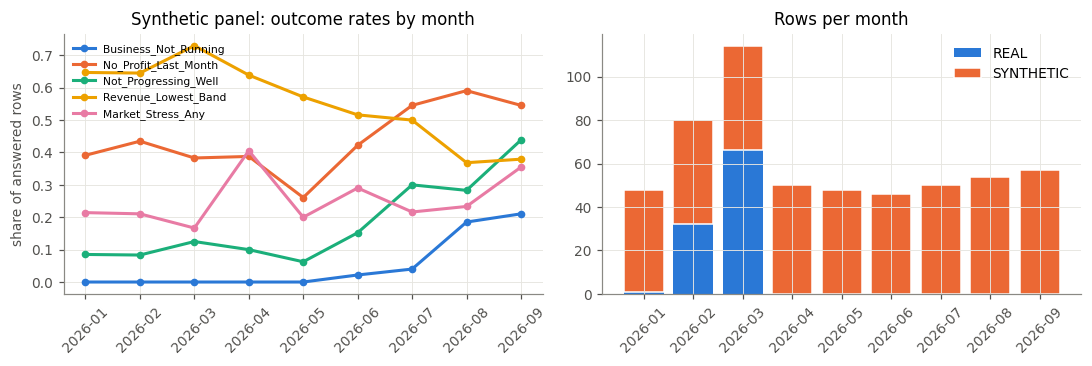

'/content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs/figures/eda_outcomes_over_time.png'

In [18]:
T_COLS = ["T_Business_Not_Running", "T_No_Profit_Last_Month", "T_Not_Progressing_Well", "T_Revenue_Lowest_Band",
          "T_Sales_Below_Expected", "T_High_Input_Cost", "T_Inputs_Unavailable", "T_Market_Stress_Any"]
rates = raw.groupby("Row_Basis")[T_COLS].mean().T.round(3); display(rates)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
syn_month = raw[IS_SYN].groupby("Month")[T_COLS[:4] + ["T_Market_Stress_Any"]].mean()
for i, c in enumerate(syn_month.columns): axes[0].plot(syn_month.index, syn_month[c], marker="o", ms=4, label=c[2:], color=SERIES[i])
axes[0].set_title("Synthetic panel: outcome rates by month"); axes[0].set_ylabel("share of answered rows"); axes[0].legend(frameon=False, fontsize=7); axes[0].tick_params(axis="x", rotation=45)
cnt = raw.groupby(["Month", "Row_Basis"]).size().unstack(fill_value=0)
axes[1].bar(cnt.index, cnt.iloc[:, 0], label=cnt.columns[0][:4], color=SERIES[0])
axes[1].bar(cnt.index, cnt.iloc[:, 1], bottom=cnt.iloc[:, 0], label=cnt.columns[1][:9], color=SERIES[1], edgecolor="white", linewidth=1)
axes[1].set_title("Rows per month"); axes[1].legend(frameon=False); axes[1].tick_params(axis="x", rotation=45)
savefig("eda_outcomes_over_time.png")

Real and synthetic outcome rates are close (the source notes they "imitate" each other). The synthetic panel shows a **strong deterioration after mid-2026** (business-not-running and not-progressing rise sharply in Jul–Sep). A chronological split will therefore face **distribution shift**: later test months are riskier than training months. This is realistic for forecasting, but it also means the test score partly measures how the synthetic generator drifts.

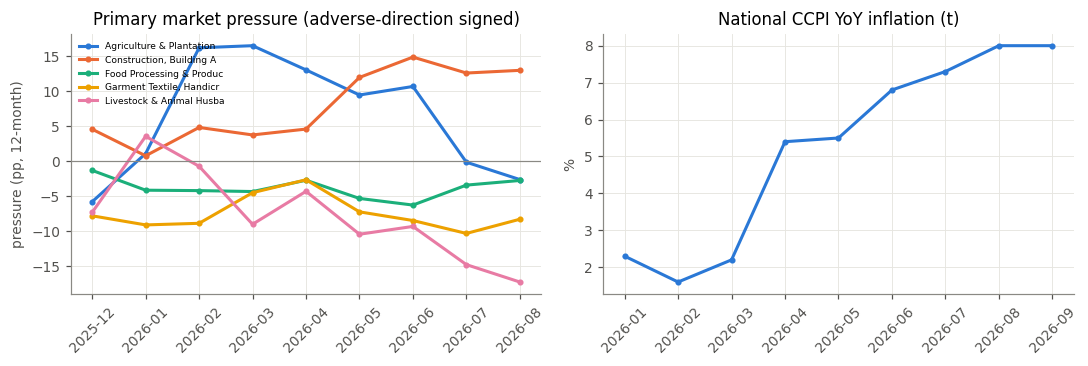

,Month,Macro_CCPI_YoY_Inflation_t,Macro_Petrol92_Price_t,Macro_AutoDiesel_Price_t
47,2026-01,2.3,294.00,278.68
0,2026-02,1.6,292.00,277.00
19,2026-03,2.2,336.16,322.10
102,2026-04,5.4,398.00,382.00
111,2026-05,5.5,410.00,391.84
103,2026-06,6.8,433.33,406.17
104,2026-07,7.3,414.00,382.00
105,2026-08,8.0,413.52,382.00
106,2026-09,8.0,399.00,382.00


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for i, (cat, g) in enumerate(mkt_obs.groupby("Category_Key")):
    axes[0].plot(g.Month, g.Primary_Pressure, marker="o", ms=3, label=cat.title()[:24], color=SERIES[i])
axes[0].axhline(0, color="#8a8984", lw=.8); axes[0].set_title("Primary market pressure (adverse-direction signed)"); axes[0].set_ylabel("pressure (pp, 12-month)")
axes[0].legend(frameon=False, fontsize=6); axes[0].tick_params(axis="x", rotation=45)
mac = raw.drop_duplicates("Month").sort_values("Month")
axes[1].plot(mac.Month, mac.Macro_CCPI_YoY_Inflation_t, marker="o", ms=3, color=SERIES[0], label="CCPI YoY inflation %")
axes[1].set_title("National CCPI YoY inflation (t)"); axes[1].set_ylabel("%"); axes[1].tick_params(axis="x", rotation=45)
savefig("eda_market_series.png")
display(mac[["Month", "Macro_CCPI_YoY_Inflation_t", "Macro_Petrol92_Price_t", "Macro_AutoDiesel_Price_t"]])

Market pressure varies across categories (Agriculture under strong output-price pressure Feb–Jun 2026; Construction input-cost pressure from May). National inflation and fuel prices move little within the 9-month window, so macro variables carry almost only **time** information — they cannot be distinguished from a month index and add little cross-sectional signal.

Market_tier_t,Low,Medium,High
Outcome,,,
T_High_Input_Cost,0.064,0.125,0.043
T_Market_Stress_Any,0.266,0.280,0.182
T_No_Profit_Last_Month,0.479,0.419,0.196
T_Sales_Below_Expected,0.206,0.240,0.140


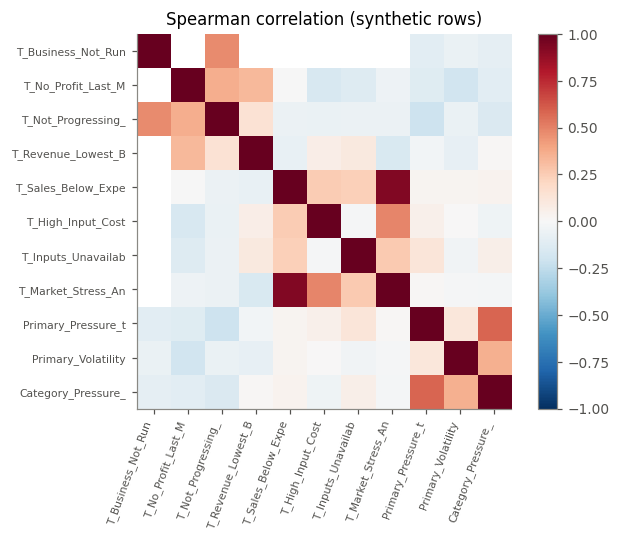

'/content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs/figures/eda_correlation.png'

In [20]:
syn = raw[IS_SYN]
dir_tab = []
for t in ["T_Market_Stress_Any", "T_No_Profit_Last_Month", "T_Sales_Below_Expected", "T_High_Input_Cost"]:
    for tier in ["Low", "Medium", "High"]:
        s_ = syn.loc[syn.Primary_Pressure_Tier_t == tier, t]
        dir_tab.append({"Outcome": t, "Market_tier_t": tier, "Rate": round(s_.mean(), 3), "N_answered": int(s_.notna().sum())})
dir_tab = pd.DataFrame(dir_tab).pivot(index="Outcome", columns="Market_tier_t", values="Rate")[["Low", "Medium", "High"]]
display(dir_tab)
corrm = syn[T_COLS + ["Primary_Pressure_t", "Primary_Volatility_t", "Category_Pressure_Tier_Ord_t"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(corrm, cmap="RdBu_r", vmin=-1, vmax=1); ax.set_xticks(range(len(corrm))); ax.set_yticks(range(len(corrm)))
ax.set_xticklabels([c[:18] for c in corrm.columns], rotation=70, ha="right", fontsize=7); ax.set_yticklabels([c[:18] for c in corrm.index], fontsize=7)
ax.grid(False); plt.colorbar(im, fraction=.04); ax.set_title("Spearman correlation (synthetic rows)")
savefig("eda_correlation.png")

**Direction check.** In the synthetic rows, a *High* market-pressure tier coincides with *lower* rates of no-profit and market stress — the opposite of the economically expected direction. Either the synthetic generator did not link outcomes to market pressure, or the relationship is confounded by category and time. Market features are therefore **not expected to carry strong predictive signal**, and any model importance they receive must be read with caution. Correlations among the household outcomes are modest, so each `T_*` adds partly distinct information.

In [21]:
cat_eda = raw.assign(Cat=raw.Category_Key.fillna("(blank)")).groupby(["Cat", "Row_Basis"]).agg(
    rows=("Month", "size"), no_profit=("T_No_Profit_Last_Month", "mean"), not_running=("T_Business_Not_Running", "mean"),
    market_stress=("T_Market_Stress_Any", "mean"), has_market_feature=("Primary_Pressure_t", lambda s: s.notna().mean())).round(3)
display(cat_eda)
lag_rows = []
s_sorted = syn.sort_values(["household_key", "Month"])
for t in T_COLS[:5] + ["T_Market_Stress_Any"]:
    for k in (1, 3, 6):
        nxt = s_sorted.groupby("household_key")[t].shift(-k)
        lag_rows.append({"Outcome": t, "Row_lag": k, "Autocorr": round(s_sorted[t].corr(nxt), 3)})
display(pd.DataFrame(lag_rows).pivot(index="Outcome", columns="Row_lag", values="Autocorr"))

rows  no_profit  not_running  market_stress  has_market_feature
Cat                               Row_Basis                                                                                    
(blank)                           REAL (not tagged synthetic)     62      0.344        0.016          0.106               0.000
AGRICULTURE & PLANTATION CROPS    REAL (not tagged synthetic)      9      0.833        0.222          0.143               1.000
                                  SYNTHETIC (tagged in source)    96      0.382        0.062          0.222               0.885
CONSTRUCTION, BUILDING AND REPAIR SYNTHETIC (tagged in source)    59      0.463        0.034          0.256               0.864
FISHERIES & AQUACULTURE           REAL (not tagged synthetic)      1      0.000        0.000          0.000               0.000
FOOD PROCESSING & PRODUCTION      REAL (not tagged synthetic)      1        NaN        1.000            NaN               1.000
                                  SYNTHETIC (tagged in source)    54      0.511        0.093          0.424               0.852
GARMENT TEXTILE, HANDICRAFTS      REAL (not tagged synthetic)      7      0.250        0.286          0.500               1.000
                                  SYNTHETIC (tagged in source)    76      0.493        0.105          0.159               0.895
LIVESTOCK & ANIMAL HUSBANDRY      REAL (not tagged synthetic)      5      0.667        0.000          0.500               1.000
                                  SYNTHETIC (tagged in source)    54      0.396        0.037          0.262               0.852
MISCELLANEOUS                     REAL (not tagged synthetic)      1      0.000        0.000          1.000               0.000
OTHER                             REAL (not tagged synthetic)     11      0.857        0.273          0.571               0.000
                                  SYNTHETIC (tagged in source)    49      0.468        0.041          0.212               0.000
TRADE                             REAL (not tagged synthetic)      2      0.000        0.000          0.500               0.000
                                  SYNTHETIC (tagged in source)    60      0.390        0.000          0.289               0.000

Row_lag,1,3,6
Outcome,,,
T_Business_Not_Running,0.710,0.191,NaN
T_Market_Stress_Any,0.108,-0.110,-0.117
T_No_Profit_Last_Month,0.557,0.017,-0.765
T_Not_Progressing_Well,0.414,0.047,0.027
T_Revenue_Lowest_Band,0.828,0.598,-0.080
T_Sales_Below_Expected,0.055,-0.055,-0.048


**Persistence.** Within synthetic households, outcomes are strongly autocorrelated at one step (e.g. revenue band, business-not-running), but the dependence fades by three to six steps for most outcomes. A **persistence baseline** (future risk = current risk) is therefore the meaningful benchmark any model must beat, and we expect 6-month prediction to be harder than 3-month prediction.

**Outliers.** Numeric columns are mostly coded answers, market indices and GPS metadata; no implausible ages or dates were found (Section 8). Extreme market-pressure values (e.g. Agriculture −16% price change) are genuine market moves, not errors, and are retained.

## 8. Data-quality assessment

In [22]:
dq = []
def add(check, result, status, action): dq.append({"Check": check, "Result": result, "Status": status, "Action": action})
add("Full-row duplicates", int(raw.duplicated().sum()), "OK" if raw.duplicated().sum() == 0 else "ISSUE", "None needed" )
dup_hm = raw[IS_SYN].duplicated(["household_key", "Month"]).sum()
add("Duplicate (household_key, Month) in synthetic panel", int(dup_hm), "OK" if dup_hm == 0 else "ISSUE", "None needed" if dup_hm == 0 else "Keep latest submission")
add("_uuid unique", bool(raw["_uuid"].is_unique), "OK", "Used as row-level trace key")
mp = pd.to_datetime(raw["Month"] + "-01", errors="coerce")
add("monitoring_period/Month parse", f"{int(mp.isna().sum())} invalid", "OK" if mp.notna().all() else "ISSUE", "Parsed to monthly period")
vd = pd.to_datetime(raw["Date of SDO household visit"], errors="coerce")
add("Visit date falls in Month", f"{int((vd.dt.to_period('M').astype(str) != raw.Month).sum())} mismatches; {int(vd.isna().sum())} unparseable", "OK", "Month confirmed as monthly monitoring index")
age = pd.to_numeric(raw["1.7. Age of the Empowerment Program Participant"], errors="coerce")
add("Participant age plausible (16-80)", f"range {age.min():.0f}-{age.max():.0f}; {int(((age < 16) | (age > 80)).sum())} outside", "OK" if ((age < 16) | (age > 80)).sum() == 0 else "REVIEW", "None")
add("Category blank", int(raw.Category_Key.isna().sum()), "ISSUE", "Kept as 'Unassigned'; not inferred (all are real rows)")
add("Category labels outside programme list", "FISHERIES & AQUACULTURE (1), MISCELLANEOUS (1)", "ISSUE", "Mapped to programme category 'Other' with sub-activity retained")
add("Garment & Textile vs Handicrafts", "single combined source key", "LIMITATION", "Kept combined; sub-activity from 3.2 retained")
add("District case variants", str(raw["1.10. Participant District"].dropna().unique().tolist()), "ISSUE", "Title-cased (COLOMBO→Colombo)")
add("Apostrophe variants in answers", "curly vs straight 'Don’t know'", "ISSUE", "Normalised to straight apostrophe")
add("Real rows without household identifier", int(raw.loc[IS_REAL, "household_key"].isna().sum()), "CRITICAL", "Real rows cannot enter 3M/6M targets")
add("Rows tagged synthetic", int(IS_SYN.sum()), "CRITICAL", "Kept and flagged; models trained on synthetic only, flagged as non-evidence")
add("Empty columns (100% missing)", int((miss == 1).sum()), "INFO", "Excluded from modelling")
const_cols = [c for c in raw.columns if raw[c].nunique(dropna=True) == 1]
add("Constant non-empty columns", len(const_cols), "INFO", "Excluded from modelling")
add("Synthetic panel gaps (missing months within household span)",
    int(sum((g.Month.apply(lambda m: pd.Period(m, 'M').ordinal).max() - g.Month.apply(lambda m: pd.Period(m, 'M').ordinal).min() + 1) - g.Month.nunique()
            for _, g in raw[IS_SYN].groupby("household_key"))), "INFO", "No imputation of missing visits; targets require an exact-month visit")
add("Market features after 2026-08", int(raw.loc[raw.Month > "2026-08", "Primary_Pressure_t"].notna().sum()), "INFO", "Structural: market data end 2026-08; missing indicator added")
Data_Quality_Checks = pd.DataFrame(dq); Data_Quality_Checks

,Check,Result,Status,Action
0,Full-row duplicates,0,OK,None needed
1,"Duplicate (household_key, Month) in synthetic panel",0,OK,None needed
2,_uuid unique,True,OK,Used as row-level trace key
3,monitoring_period/Month parse,0 invalid,OK,Parsed to monthly period
4,Visit date falls in Month,0 mismatches; 0 unparseable,OK,Month confirmed as monthly monitoring index
5,Participant age plausible (16-80),range 28-48; 0 outside,OK,None
6,Category blank,62,ISSUE,Kept as 'Unassigned'; not inferred (all are real rows)
7,Category labels outside programme list,"FISHERIES & AQUACULTURE (1), MISCELLANEOUS (1)",ISSUE,Mapped to programme category 'Other' with sub-activity r...
8,Garment & Textile vs Handicrafts,single combined source key,LIMITATION,Kept combined; sub-activity from 3.2 retained
9,District case variants,"['Ratnapura', 'Ampara', 'Monaragala', 'COLOMBO', 'Badull...",ISSUE,Title-cased (COLOMBO→Colombo)


## 9. Data cleaning and documented transformations
Cleaning is applied to a copy (`clean`). Original columns are never overwritten — cleaned versions are new columns with a `C_` prefix. No rows are deleted. No imputation is done here (it is fitted inside the model pipelines on training data only).

In [23]:
clean = raw.copy()
TRANSFORM_LOG = []
def log(step, cols, rule, rows): TRANSFORM_LOG.append({"Step": step, "Columns": cols, "Rule": rule, "Rows_affected": int(rows)})

clean["Is_Synthetic"] = IS_SYN.astype(int)
clean["Month_Period"] = pd.PeriodIndex(clean["Month"], freq="M")
clean["Month_Ord"] = clean["Month_Period"].apply(lambda p: p.ordinal)
log("Add", "Is_Synthetic, Month_Period, Month_Ord", "From Row_Basis and Month", len(clean))

clean["C_District"] = clean["1.10. Participant District"].astype(str).str.strip().str.title().where(clean["1.10. Participant District"].notna())
log("Normalise", "C_District", "strip + title case", (clean["C_District"] != clean["1.10. Participant District"]).sum())

clean["Programme_Category"] = clean["Category_Key"].map(KEY_TO_PROG).fillna("Unassigned")
log("Map", "Programme_Category", "Category_Key → programme list; FISHERIES/MISCELLANEOUS → Other; blank → Unassigned", len(clean))

act = clean["3.2. Primary livelihood activity"].fillna(clean["If OTHER, please specify"])
clean["Sub_Activity"] = act
def other_subtype(r):
    a = str(r["Sub_Activity"]).lower()
    if r["Category_Key"] == "FISHERIES & AQUACULTURE" or "fish" in a: return "Fisheries (in Other)"
    if "retail" in a: return "Home-based retail (trade-like, in Other)"
    if r["Category_Key"] in ("OTHER", "MISCELLANEOUS"): return "Other - unclassified/mixed"
    return ""
clean["Other_Subtype"] = clean.apply(other_subtype, axis=1)
log("Derive", "Sub_Activity, Other_Subtype", "3.2 activity (or free-text); keyword split of 'Other'", (clean.Other_Subtype != "").sum())

ans_cols = [c for c in raw.columns if raw[c].dtype == object and raw[c].astype(str).str.contains("’", regex=False).any()]
for c in ans_cols:
    clean["C_" + c] = norm_ans(clean[c])
log("Normalise", f"{len(ans_cols)} answer columns → C_*", "curly apostrophe → straight", sum(clean[c].astype(str).str.contains("’", regex=False).sum() for c in ans_cols))
def C(c): return "C_" + c if "C_" + c in clean.columns else c

clean["Grant_Date"] = pd.to_datetime(clean["6.2. Grant Received date"], errors="coerce")
clean["Visit_Date"] = pd.to_datetime(clean["Date of SDO household visit"], errors="coerce")
log("Parse", "Grant_Date, Visit_Date", "to datetime", clean.Grant_Date.notna().sum())

EMPTY_COLS = [c for c in raw.columns if raw[c].isna().all()]
CONST_COLS = [c for c in raw.columns if raw[c].nunique(dropna=True) == 1]
log("Flag", "EMPTY_COLS / CONST_COLS", "excluded from modelling, kept in data", len(EMPTY_COLS) + len(CONST_COLS))

# QC: original values untouched
orig_unchanged = all(raw[c].equals(RAW_FROZEN[c]) for c in raw.columns) and all(clean[c].equals(RAW_FROZEN[c]) for c in raw.columns)
assert orig_unchanged, "STOP: original values were modified"
assert clean["_uuid"].is_unique and len(clean) == len(raw)
Transform_Log = pd.DataFrame(TRANSFORM_LOG)
Data_Quality_Checks = pd.concat([Data_Quality_Checks, pd.DataFrame([
    {"Check": "QC: original source columns unchanged in clean copy", "Result": orig_unchanged, "Status": "OK", "Action": "-"},
    {"Check": "QC: row count preserved / _uuid traceable", "Result": f"{len(clean)} rows", "Status": "OK", "Action": "-"},
    {"Check": "QC: cleaning uses no test-set or future information", "Result": "row-wise rules only", "Status": "OK", "Action": "-"}])], ignore_index=True)
Transform_Log

,Step,Columns,Rule,Rows_affected
0,Add,"Is_Synthetic, Month_Period, Month_Ord",From Row_Basis and Month,547
1,Normalise,C_District,strip + title case,6
2,Map,Programme_Category,Category_Key → programme list; FISHERIES/MISCELLANEOUS →...,547
3,Derive,"Sub_Activity, Other_Subtype",3.2 activity (or free-text); keyword split of 'Other',71
4,Normalise,13 answer columns → C_*,curly apostrophe → straight,522
5,Parse,"Grant_Date, Visit_Date",to datetime,203
6,Flag,EMPTY_COLS / CONST_COLS,"excluded from modelling, kept in data",77


## 10. Livelihood-specific indicator analysis

In [24]:
ECON = {
 "PPI A: Agriculture": ("Producer (farm-gate) price index for agricultural output", "Fall in selling price"),
 "PPI 014 Animal production": ("Producer price of animal products (milk, eggs, meat)", "Fall in selling price"),
 "PPI 10 Manufacture of food products": ("Producer price of processed food (output); agricultural inputs not captured", "Fall in selling price (input costs not measured)"),
 "PPI 14 Manufacture of wearing apparel": ("Producer price of apparel (output)", "Fall in selling price"),
 "PPI 23 Non-metallic minerals (cement/glass/bricks)": ("Price of cement/bricks/glass = main input cost for construction & repair", "Rise in input cost"),
}
ind_rows = []
for pc in PROG_CATS:
    ks = keys_for(pc); sub = clean[clean.Category_Key.isin(ks)]
    em = mkt_obs[mkt_obs.Category_Key.isin(ks)]
    if len(em):
        ind = em.Primary_Indicator.iloc[0]; meaning, adverse = ECON.get(ind, ("", ""))
        ind_rows.append({"Livelihood_category": pc, "Indicator_column": "Primary_Pressure_t / Primary_Pct_Change_12M_t", "Indicator": ind,
                         "Economic_meaning": meaning, "Expected_adverse_direction": adverse, "Direction_source": "Verified sign rule in data",
                         "Historical_coverage": f"{em.Month.min()}..{em.Month.max()} in table (48-month history upstream, not supplied)",
                         "Missing_pct_rows": round(100 * sub.Primary_Pressure_t.isna().mean(), 1), "Observed_or_proxy": "Proxy (national PPI, not local prices)",
                         "Evidence_supported": "Partially (direction verified; thresholds partially)", "Expert_validation_required": "Yes - confirm PPI line and thresholds"})
        ind_rows.append({"Livelihood_category": pc, "Indicator_column": "Primary_Volatility_t", "Indicator": ind + " volatility",
                         "Economic_meaning": "Instability of the price line (formula not documented)", "Expected_adverse_direction": "Higher volatility",
                         "Direction_source": "Assumed (tier rises with value)", "Historical_coverage": "same", "Missing_pct_rows": round(100 * sub.Primary_Volatility_t.isna().mean(), 1),
                         "Observed_or_proxy": "Proxy", "Evidence_supported": "Partially", "Expert_validation_required": "Yes - formula unknown"})
    if pc in ("Transport & Logistics", "Construction, Building & Repair", "Trade", "Agriculture & Plantation Crops"):
        ind_rows.append({"Livelihood_category": pc, "Indicator_column": "Macro_AutoDiesel_Price_t / Macro_Petrol92_Price_t", "Indicator": "National pump prices",
                         "Economic_meaning": "Fuel cost for transport, machinery, delivery", "Expected_adverse_direction": "Rise in fuel price",
                         "Direction_source": "Economic reasoning (not in existing method)", "Historical_coverage": "all months (national)",
                         "Missing_pct_rows": round(100 * sub.Macro_AutoDiesel_Price_t.isna().mean(), 1) if len(sub) else 100.0, "Observed_or_proxy": "Observed national price",
                         "Evidence_supported": "No household-level evidence (little variation in window)", "Expert_validation_required": "Yes"})
    ind_rows.append({"Livelihood_category": pc, "Indicator_column": "Macro_CCPI_YoY_Inflation_t", "Indicator": "National CCPI inflation",
                     "Economic_meaning": "General cost of living / input prices", "Expected_adverse_direction": "Rise (cost) — but can also lift selling prices",
                     "Direction_source": "Ambiguous; not in existing method", "Historical_coverage": "all months", "Missing_pct_rows": 0.0 if len(sub) else 100.0,
                     "Observed_or_proxy": "Observed national", "Evidence_supported": "Weak", "Expert_validation_required": "Yes"})
    if len(sub):
        ind_rows.append({"Livelihood_category": pc, "Indicator_column": "T_Sales_Below_Expected, T_High_Input_Cost, T_Inputs_Unavailable, T_No_Profit_Last_Month, T_Revenue_Lowest_Band",
                         "Indicator": "Household-reported market/performance stress", "Economic_meaning": "Directly observed household market outcome",
                         "Expected_adverse_direction": "1 = adverse (same for all categories, by question design)", "Direction_source": "Verified T_* rules",
                         "Historical_coverage": f"{sub.Month.min()}..{sub.Month.max()}", "Missing_pct_rows": round(100 * sub.T_Market_Stress_Any.isna().mean(), 1),
                         "Observed_or_proxy": "Directly observed (self-report)", "Evidence_supported": "Yes", "Expert_validation_required": "Rule weights: yes"})
    else:
        ind_rows.append({"Livelihood_category": pc, "Indicator_column": "none", "Indicator": "none", "Economic_meaning": "No monitoring rows for this category",
                         "Expected_adverse_direction": "", "Direction_source": "", "Historical_coverage": "none", "Missing_pct_rows": 100.0,
                         "Observed_or_proxy": "", "Evidence_supported": "No", "Expert_validation_required": "Data collection required"})
Category_Indicator_Register = pd.DataFrame(ind_rows)
display(Category_Indicator_Register.groupby("Livelihood_category").size().rename("indicators"))
print(clean.loc[clean.Programme_Category == "Other", ["Other_Subtype", "Is_Synthetic"]].value_counts())

,indicators
Livelihood_category,
Agriculture & Plantation Crops,5
Beauty & Wellness,2
"Construction, Building & Repair",5
Food Processing & Production,4
Garment & Textile,4
Handicrafts,4
Livestock & Animal Husbandry,4
Other,2
Trade,3


Other_Subtype                             Is_Synthetic
Home-based retail (trade-like, in Other)  1               26
Fisheries (in Other)                      1               23
Other - unclassified/mixed                0               11
Fisheries (in Other)                      0                1
Home-based retail (trade-like, in Other)  0                1
Name: count, dtype: int64


**Interpretation.** Adverse directions differ by category and follow the verified existing rule (output-price falls for producers; input-cost rises for construction). Food processing is measured only by its *output* price; its agricultural input costs are not captured — flagged for expert review. **"Other" is heterogeneous**: in the synthetic panel it is mostly home-based retail (trade-like) and inland fishing; in the real rows it includes brick-making, welding, tea cultivation and spice processing. A single market rule is not appropriate for it, and it has no market evidence line. **Transport & Logistics and Beauty & Wellness have no rows at all**; nothing can be estimated for them. **Garment & Textile and Handicrafts** are one combined source key and cannot be separated reliably.

## 11. Temporal and project-duration analysis

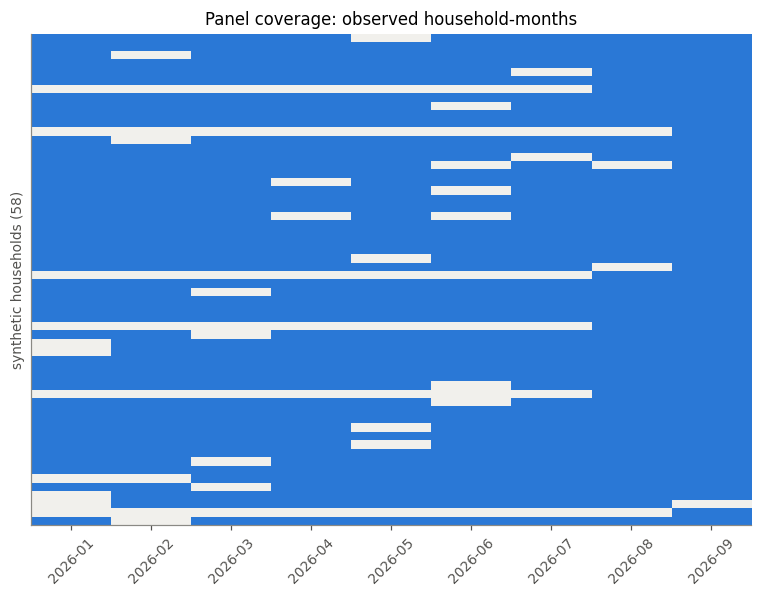

,Horizon_months,Tolerance_months,Rows_with_future_visit
0,3,0,270
1,3,1,336
2,6,0,138
3,6,1,192


Months since grant (where grant date reported):
count    203.0
mean       3.4
std        2.6
min        0.0
25%        1.3
50%        2.7
75%        4.9
max       10.7
dtype: float64


In [25]:
syn_c = clean[clean.Is_Synthetic == 1].copy()
cov = syn_c.pivot_table(index="household_key", columns="Month", values="_uuid", aggfunc="count").notna()
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.imshow(cov.values, aspect="auto", cmap=matplotlib.colors.ListedColormap(["#f1f0ec", SERIES[0]]))
ax.set_xticks(range(cov.shape[1])); ax.set_xticklabels(cov.columns, rotation=45); ax.set_yticks([]); ax.grid(False)
ax.set_ylabel("synthetic households (58)"); ax.set_title("Panel coverage: observed household-months")
savefig("temporal_panel_coverage.png")
# exact horizon availability
o = set(zip(syn_c.household_key, syn_c.Month_Ord))
avail = []
for h in (3, 6):
    for tol in (0, 1):
        n = sum(any((k, m + h + d) in o for d in range(-tol, tol + 1)) for k, m in o)
        avail.append({"Horizon_months": h, "Tolerance_months": tol, "Rows_with_future_visit": n})
avail = pd.DataFrame(avail); display(avail)
g_mon = (clean.Visit_Date - clean.Grant_Date).dt.days / 30.44
print("Months since grant (where grant date reported):"); print(g_mon.describe().round(1))

**Target-date matching decision.** Monitoring is strictly monthly (visit date always falls in `Month`). Allowing ±1 month tolerance would add only a few rows (table above) while blurring a 3-month horizon into 2–4 months. We therefore use **exact calendar-month matching (tolerance 0)**: the 3M target of a visit in month *t* is the same household's visit in month *t+3*. Missing future visits leave the target unassigned rather than being filled.

**Project duration.** No explicit project-duration variable exists. Two documented proxies are used: *months since the household's first observed visit* (panel tenure) and *months since grant received* (6.2, available for ~37% of rows, carried forward only from visits at or before *t*).

## 12. Household risk rule (applied at every visit) — basis for the future targets
Because no household Low/Medium/High label exists, a transparent rule is built **only from the verified `T_*` indicators** (no new weights, no fitted thresholds):

| Class | Primary rule (Variant A) |
|---|---|
| **High** | Business not running (`T_Business_Not_Running`=1) **or** ≥2 of the three stress signals {`T_No_Profit_Last_Month`, `T_Not_Progressing_Well`, `T_Market_Stress_Any`} |
| **Medium** | exactly 1 of the three stress signals |
| **Low** | business running and all three signals answered and = 0 |
| **Unassigned** | blanks / "Don't know" make the class undetermined |

**Evidence-sufficiency rule:** a class is assigned only if it is the same under the best case (blanks = 0) and the worst case (blanks = 1). Observations are never forced into a class.

**Why these signals.** They are the existing, verified outcome definitions; they cover the market channel (`T_Market_Stress_Any`, itself the existing composite of sales-below-expected / high input cost / input unavailability), financial performance (no profit) and the coach's independent assessment (not progressing). Equal weights (a simple count) are used because no evidence for differential weights exists; this is flagged for expert validation. `T_Revenue_Lowest_Band` is **excluded from the primary rule**: 60% of answered rows fall in the lowest band and 31% answer "Don't know", so it mainly reflects business scale rather than stress — it is tested in sensitivity Variant B.

**Category specificity.** The form questions and their adverse directions are identical across categories, so the household rule is category-agnostic by design. Category-specific market risk is carried by the preserved market-tier method (features + auxiliary analysis). Category-specific household thresholds would need expert input and are not invented here.

In [26]:
def risk_rule(df, variant="A"):
    """Return (class string or NaN, n_pos, n_unknown) per row. Variants: A primary; B +revenue band; C market-channel only; E strict High."""
    bnr = df["T_Business_Not_Running"]
    if variant == "A": sig = ["T_No_Profit_Last_Month", "T_Not_Progressing_Well", "T_Market_Stress_Any"]; hi = 2
    elif variant == "B": sig = ["T_No_Profit_Last_Month", "T_Not_Progressing_Well", "T_Market_Stress_Any", "T_Revenue_Lowest_Band"]; hi = 2
    elif variant == "C": sig = ["T_Market_Stress_Any", "T_No_Profit_Last_Month"]; hi = 2
    elif variant == "E": sig = ["T_No_Profit_Last_Month", "T_Not_Progressing_Well", "T_Market_Stress_Any"]; hi = 3
    S = df[sig]
    npos = (S == 1).sum(axis=1); nunk = S.isna().sum(axis=1)
    def cls(n): return np.where(n >= hi, 2, np.where(n >= 1, 1, 0))
    lo_c, hi_c = cls(npos), cls(npos + nunk)
    out = np.where(lo_c == hi_c, lo_c, -1).astype(float)
    out = np.where(bnr == 1, 2, out); out = np.where(bnr.isna() & (out < 2), -1, out)
    lab = pd.Series(np.where(out < 0, np.nan, out), index=df.index).map(dict(enumerate(CLASSES)))
    return lab, npos, nunk

for v in "ABCE":
    clean[f"Risk_Class_t_{v}"], _, _ = risk_rule(clean, v)
clean["Risk_Class_t"] = clean["Risk_Class_t_A"]
clean["Risk_Ord_t"] = clean["Risk_Class_t"].map(CLASS_TO_INT)
_, clean["Risk_Signal_Count_t"], clean["Risk_Signal_Unknown_t"] = risk_rule(clean, "A")
display(pd.crosstab(clean.Risk_Class_t.fillna("Unassigned"), clean.Row_Basis, margins=True))

Row_Basis,REAL (not tagged synthetic),SYNTHETIC (tagged in source),All
Risk_Class_t,,,
High,22,97,119
Low,36,144,180
Medium,19,109,128
Unassigned,22,98,120
All,99,448,547


## 13. Feature engineering (prediction-time features only)
All features for a visit in month *t* use that visit and **earlier visits of the same household only** (sorted by calendar month, windows defined in months, not rows). Market features are the source columns for month *t* and *t−1*. `build_features` is re-run on data truncated at each month in Section 16 to prove no future information enters.

In [27]:
ORD_MAPS = {
    "3.4. In the last month, on average how many hours a day did you work in the livelihood?": {"1-4 hours a day": 1, "5-8 hours a day": 2, "9+ hours a day": 3},
    "3.5. In the last month, how often did you write your business records (expenses, sales, loans…etc.)?": {"I don't keep any written records": 0, "A few times a month": 1, "Once or twice a week": 2, "Daily": 3},
    "6.1. Has the grant been received?": {"No": 0, "Yes - Not fully utilized": 1, "Yes - Fully utilized but all bills are not settled": 2, "Yes - Fully utilized": 3, "Yes - Fully utilized and all bills were settled": 3},
}
YN = {"Yes": 1, "No": 0}
YN_COLS = {"F_Borrowed_t": "3.6. In the last month, did you borrow any money to help you operate the business (new borrowing)?",
           "F_Saved_t": "4.4. In the last month, were you able to save money?",
           "F_Cyclone_Affected_t": "2.1. Have you been affected by the Cyclone?",
           "F_Female_Head": "1.3. Is the household headed by a female?",
           "F_Asset_Lost_t": "3.10.2. Lost a livelihood asset (e.g., equipment failure, livestock died, loss of harvest, etc.)",
           "F_Storage_Transport_Issue_t": "3.10.5. Storage or transportation issues",
           "F_Machinery_Issue_t": "3.10.6. Machinery or equipment not functioning",
           "F_Natural_Disaster_t": "3.10.7. Natural disaster"}

def build_features(df_in):
    """Prediction-time features. Uses only rows with Month_Ord <= row's own Month_Ord within household."""
    d = df_in.sort_values(["household_key", "Month_Ord", "_uuid"]).copy()
    F = pd.DataFrame(index=d.index)
    # current-visit household signals
    for t in T_COLS: F["F_" + t[2:] + "_t"] = d[t]
    F["F_Risk_Ord_t"] = d["Risk_Ord_t"]; F["F_Risk_Signal_Count_t"] = d["Risk_Signal_Count_t"]; F["F_Risk_Unknown_t"] = d["Risk_Signal_Unknown_t"]
    F["F_Hours_Ord_t"] = norm_ans(d[list(ORD_MAPS)[0]]).map(ORD_MAPS[list(ORD_MAPS)[0]])
    F["F_Records_Ord_t"] = norm_ans(d[list(ORD_MAPS)[1]]).map(ORD_MAPS[list(ORD_MAPS)[1]])
    F["F_Grant_Status_Ord_t"] = norm_ans(d[list(ORD_MAPS)[2]]).map(ORD_MAPS[list(ORD_MAPS)[2]])
    for f, c in YN_COLS.items(): F[f] = norm_ans(d[c]).map(YN)
    F["F_Age"] = pd.to_numeric(d["1.7. Age of the Empowerment Program Participant"], errors="coerce")
    F["F_Female_Participant"] = d["1.6. Gender of the Empowerment Program Participant"].map({"Female": 1, "Male": 0})
    # history (same household, strictly earlier months)
    g = d.groupby("household_key", sort=False)
    prev_ord = g["Month_Ord"].shift(1)
    F["F_Months_Since_Prev_Visit"] = d["Month_Ord"] - prev_ord
    for t in ["Risk_Ord_t", "T_No_Profit_Last_Month", "T_Market_Stress_Any", "T_Not_Progressing_Well", "T_Business_Not_Running"]:
        F["F_Prev_" + t.replace("T_", "").replace("_t", "")] = g[t].shift(1)
    F["F_Risk_Change_vs_Prev"] = F["F_Risk_Ord_t"] - F["F_Prev_Risk_Ord"]
    F["F_Tenure_Months"] = d["Month_Ord"] - g["Month_Ord"].transform("cummin")
    F["F_N_Prior_Visits"] = g.cumcount()
    # rolling 3-calendar-month window [t-2, t]
    roll = {"F_Risk_Mean_3M_Window": "Risk_Ord_t", "F_NoProfit_Rate_3M_Window": "T_No_Profit_Last_Month",
            "F_MarketStress_Rate_3M_Window": "T_Market_Stress_Any", "F_High_Count_6M_Window": "Risk_Ord_t"}
    for f in roll: F[f] = np.nan
    for hk, gi in d.groupby("household_key", sort=False):
        if pd.isna(hk): continue
        mo = gi["Month_Ord"].values
        ro = gi["Risk_Ord_t"].values.astype(float); npf = gi["T_No_Profit_Last_Month"].values.astype(float)
        ms = gi["T_Market_Stress_Any"].values.astype(float)
        def nmean(v): return float(np.nanmean(v)) if np.any(~np.isnan(v)) else np.nan
        for i, idx in enumerate(gi.index):
            w3 = (mo <= mo[i]) & (mo >= mo[i] - 2); w6 = (mo <= mo[i]) & (mo >= mo[i] - 5)
            F.at[idx, "F_Risk_Mean_3M_Window"] = nmean(ro[w3])
            F.at[idx, "F_NoProfit_Rate_3M_Window"] = nmean(npf[w3])
            F.at[idx, "F_MarketStress_Rate_3M_Window"] = nmean(ms[w3])
            F.at[idx, "F_High_Count_6M_Window"] = float(np.sum(ro[w6] == 2))
    # grant timing: carry forward grant date reported at visits <= t only
    gd = g["Grant_Date"].transform(lambda s: s.ffill())
    F["F_Months_Since_Grant"] = ((d["Visit_Date"] - gd).dt.days / 30.44).where(lambda x: x >= 0)
    # market features at t and t-1 (source columns, joined by month & category)
    F["F_Mkt_Pressure_t"] = d["Primary_Pressure_t"]; F["F_Mkt_Volatility_t"] = d["Primary_Volatility_t"]
    F["F_Mkt_Pressure_Change_1M"] = d["Primary_Pressure_t"] - d["Primary_Pressure_t_minus_1"]
    F["F_Mkt_Volatility_Change_1M"] = d["Primary_Volatility_t"] - d["Primary_Volatility_t_minus_1"]
    F["F_Mkt_Pressure_Tier_Ord_t"] = d["Category_Pressure_Tier_Ord_t"]; F["F_Mkt_Volatility_Tier_Ord_t"] = d["Category_Volatility_Tier_Ord_t"]
    F["F_Mkt_Pressure_Tier_Ord_t_minus_1"] = d["Category_Pressure_Tier_Ord_t_minus_1"]
    F["F_Mkt_Evidence_Missing"] = d["Primary_Pressure_t"].isna().astype(int)
    F["F_Macro_CCPI_YoY_t"] = d["Macro_CCPI_YoY_Inflation_t"]
    F["F_Macro_CCPI_YoY_Change_1M"] = d["Macro_CCPI_YoY_Inflation_t"] - d["Macro_CCPI_YoY_Inflation_t_minus_1"]
    F["F_Macro_Food_Index_Change_1M_pct"] = 100 * (d["Macro_CCPI_Food_Index_t"] / d["Macro_CCPI_Food_Index_t_minus_1"] - 1)
    F["F_Macro_Diesel_t"] = d["Macro_AutoDiesel_Price_t"]
    F["F_Macro_Diesel_Change_1M_pct"] = 100 * (d["Macro_AutoDiesel_Price_t"] / d["Macro_AutoDiesel_Price_t_minus_1"] - 1)
    # categorical
    F["F_Category"] = d["Programme_Category"]; F["F_District"] = d["C_District"]
    return F.loc[df_in.index]

feat = build_features(clean)
FEATURES_CAT = ["F_Category", "F_District"]
FEATURES_NUM = [c for c in feat.columns if c not in FEATURES_CAT]
print(len(FEATURES_NUM), "numeric +", len(FEATURES_CAT), "categorical features")
feat.loc[clean.Is_Synthetic == 1].describe().T.round(2).head(60)

51 numeric + 2 categorical features


,count,mean,std,min,25%,50%,75%,max
F_Business_Not_Running_t,448.0,0.06,0.23,0.00,0.00,0.00,0.00,1.00
F_No_Profit_Last_Month_t,411.0,0.44,0.50,0.00,0.00,0.00,1.00,1.00
F_Not_Progressing_Well_t,447.0,0.19,0.39,0.00,0.00,0.00,0.00,1.00
F_Revenue_Lowest_Band_t,280.0,0.57,0.50,0.00,0.00,1.00,1.00,1.00
F_Sales_Below_Expected_t,321.0,0.21,0.41,0.00,0.00,0.00,0.00,1.00
F_High_Input_Cost_t,395.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00
F_Inputs_Unavailable_t,386.0,0.02,0.13,0.00,0.00,0.00,0.00,1.00
F_Market_Stress_Any_t,308.0,0.25,0.44,0.00,0.00,0.00,1.00,1.00
F_Risk_Ord_t,350.0,0.87,0.82,0.00,0.00,1.00,2.00,2.00
F_Risk_Signal_Count_t,448.0,0.76,0.73,0.00,0.00,1.00,1.00,3.00


In [28]:
FEATURE_DOC = {
 "F_*_t (T_ signals)": ("T_* at visit t", "Current household outcome at prediction time", "Verified T_* columns"),
}
def doc_feature(f):
    src, formula, interp = "", "", ""
    if f.startswith("F_") and f.endswith("_t") and ("T_" + f[2:-2]) in T_COLS:
        src, formula, interp = "T_" + f[2:-2], "value at visit t", "Current-month household outcome (observed at t)"
    elif f == "F_Risk_Ord_t": src, formula, interp = "T_* via rule A", "0/1/2 = Low/Medium/High at t", "Current risk class (persistence signal)"
    elif f == "F_Risk_Signal_Count_t": src, formula, interp = "T_No_Profit, T_Not_Progressing, T_Market_Stress_Any", "count of 1s", "Intensity of current stress"
    elif f == "F_Risk_Unknown_t": src, formula, interp = "same", "count of blanks", "Answer completeness at t"
    elif f.startswith("F_Prev_"): src, formula, interp = f.replace("F_Prev_", ""), "value at previous visit of same household", "Recent history"
    elif "Window" in f: src, formula, interp = "Risk_Ord_t / T_*", "mean (or count of High) over visits in months [t-2,t] (3M) or [t-5,t] (6M)", "Smoothed recent risk"
    elif f.startswith("F_Mkt_") or f.startswith("F_Macro_"):
        src = {"F_Mkt_Pressure_t": "Primary_Pressure_t", "F_Mkt_Volatility_t": "Primary_Volatility_t", "F_Mkt_Pressure_Change_1M": "Primary_Pressure_t - Primary_Pressure_t_minus_1",
               "F_Mkt_Volatility_Change_1M": "Primary_Volatility_t - _t_minus_1", "F_Mkt_Pressure_Tier_Ord_t": "Category_Pressure_Tier_Ord_t", "F_Mkt_Volatility_Tier_Ord_t": "Category_Volatility_Tier_Ord_t",
               "F_Mkt_Pressure_Tier_Ord_t_minus_1": "Category_Pressure_Tier_Ord_t_minus_1", "F_Mkt_Evidence_Missing": "Primary_Pressure_t is blank",
               "F_Macro_CCPI_YoY_t": "Macro_CCPI_YoY_Inflation_t", "F_Macro_CCPI_YoY_Change_1M": "Macro_CCPI_YoY_Inflation_t - _t_minus_1",
               "F_Macro_Food_Index_Change_1M_pct": "Macro_CCPI_Food_Index_t / _t_minus_1", "F_Macro_Diesel_t": "Macro_AutoDiesel_Price_t", "F_Macro_Diesel_Change_1M_pct": "Macro_AutoDiesel_Price_t / _t_minus_1"}.get(f, "")
        formula, interp = "source value or difference (t vs t-1)", "Existing category-specific market pressure (preserved direction) / national macro"
    elif f in ("F_Tenure_Months", "F_N_Prior_Visits", "F_Months_Since_Prev_Visit", "F_Months_Since_Grant"):
        src, formula, interp = "Month_Ord, Grant_Date, Visit_Date", "elapsed months up to t", "Project-duration proxy"
    elif f == "F_Risk_Change_vs_Prev": src, formula, interp = "F_Risk_Ord_t - F_Prev_Risk_Ord", "difference", "Direction of recent change"
    elif f in [k for k in YN_COLS]: src, formula, interp = YN_COLS[f], "Yes=1, No=0, else blank", "Operating condition at t"
    elif f in ("F_Hours_Ord_t", "F_Records_Ord_t", "F_Grant_Status_Ord_t"): src, formula, interp = "3.4 / 3.5 / 6.1", "ordinal coding", "Effort / record-keeping / grant use"
    elif f in ("F_Age", "F_Female_Participant"): src, formula, interp = "1.7 / 1.6", "numeric / Female=1", "Participant characteristic"
    elif f in FEATURES_CAT: src, formula, interp = "Programme_Category / C_District", "one-hot in pipeline", "Category / location"
    return {"Feature": f, "Source_columns": src, "Formula": formula, "Economic_interpretation": interp,
            "Available_at_prediction_time": "Yes (t or earlier)", "Missing_pct_synthetic": round(100 * feat.loc[clean.Is_Synthetic == 1, f].isna().mean(), 1),
            "Type": "categorical" if f in FEATURES_CAT else "numeric"}
Feature_Register = pd.DataFrame([doc_feature(f) for f in feat.columns]); Feature_Register.head(10)

,Feature,Source_columns,Formula,Economic_interpretation,Available_at_prediction_time,Missing_pct_synthetic,Type
0,F_Business_Not_Running_t,T_Business_Not_Running,value at visit t,Current-month household outcome (observed at t),Yes (t or earlier),0.0,numeric
1,F_No_Profit_Last_Month_t,T_No_Profit_Last_Month,value at visit t,Current-month household outcome (observed at t),Yes (t or earlier),8.3,numeric
2,F_Not_Progressing_Well_t,T_Not_Progressing_Well,value at visit t,Current-month household outcome (observed at t),Yes (t or earlier),0.2,numeric
3,F_Revenue_Lowest_Band_t,T_Revenue_Lowest_Band,value at visit t,Current-month household outcome (observed at t),Yes (t or earlier),37.5,numeric
4,F_Sales_Below_Expected_t,T_Sales_Below_Expected,value at visit t,Current-month household outcome (observed at t),Yes (t or earlier),28.3,numeric
5,F_High_Input_Cost_t,T_High_Input_Cost,value at visit t,Current-month household outcome (observed at t),Yes (t or earlier),11.8,numeric
6,F_Inputs_Unavailable_t,T_Inputs_Unavailable,value at visit t,Current-month household outcome (observed at t),Yes (t or earlier),13.8,numeric
7,F_Market_Stress_Any_t,T_Market_Stress_Any,value at visit t,Current-month household outcome (observed at t),Yes (t or earlier),31.2,numeric
8,F_Risk_Ord_t,T_* via rule A,0/1/2 = Low/Medium/High at t,Current risk class (persistence signal),Yes (t or earlier),21.9,numeric
9,F_Risk_Signal_Count_t,"T_No_Profit, T_Not_Progressing, T_Market_Stress_Any",count of 1s,Intensity of current stress,Yes (t or earlier),0.0,numeric


## 14–15. Definition of `Risk_Label_3M` and `Risk_Label_6M`, target-date matching and eligibility
For a visit of household *k* in month *t*: `Risk_Label_hM` = rule-A class of household *k*'s visit in month *t+h* (exact calendar month). Predictors come from month *t* and earlier only. Each row receives an explicit status.

In [29]:
LAST_MONTH_ORD = int(clean.Month_Ord.max())
lookup = clean[clean.household_key.notna()].set_index(["household_key", "Month_Ord"])
lookup = lookup[~lookup.index.duplicated()]
target_rows = []
for h_name, h in HORIZONS.items():
    lab, tmonth, status, reason = [], [], [], []
    for idx, r in clean.iterrows():
        tm = r.Month_Ord + h; tmonth.append(str(pd.Period(ordinal=int(tm), freq="M")))
        if pd.isna(r.household_key):
            lab.append(np.nan); status.append("unavailable"); reason.append("No household identifier (real row) - future visit cannot be matched")
        elif tm > LAST_MONTH_ORD:
            lab.append(np.nan); status.append("unavailable"); reason.append(f"Target month beyond data end ({clean.Month.max()})")
        elif (r.household_key, tm) not in lookup.index:
            lab.append(np.nan); status.append("unavailable"); reason.append("No visit of this household in target month")
        else:
            v = lookup.loc[(r.household_key, tm), "Risk_Class_t"]
            if pd.isna(v): lab.append(np.nan); status.append("unavailable"); reason.append("Target-month answers insufficient to assign class")
            else: lab.append(v); status.append("rule-derived (synthetic)"); reason.append("")
    clean[f"Risk_Label_{h_name}"] = lab; clean[f"Target_Month_{h_name}"] = tmonth
    clean[f"Target_Status_{h_name}"] = status; clean[f"Exclusion_Reason_{h_name}"] = reason
    for v in "BCE":
        alt = []
        for idx, r in clean.iterrows():
            key = (r.household_key, r.Month_Ord + h)
            alt.append(lookup.loc[key, f"Risk_Class_t_{v}"] if pd.notna(r.household_key) and key in lookup.index else np.nan)
        clean[f"Risk_Label_{h_name}_{v}"] = alt

elig = pd.concat({h: clean.groupby(f"Exclusion_Reason_{h}").size() for h in HORIZONS}, axis=1).fillna(0).astype(int)
elig.index = elig.index.where(elig.index != "", "ELIGIBLE (label assigned)"); display(elig)
for h in HORIZONS:
    if clean[f"Risk_Label_{h}"].notna().sum() == 0: raise RuntimeError(f"STOP: no {h} targets could be constructed")
    if clean[f"Risk_Label_{h}"].nunique() < 2: raise RuntimeError(f"STOP: {h} target has <2 classes")

,3M,6M
ELIGIBLE (label assigned),219,116
No household identifier (real row) - future visit cannot be matched,99,99
No visit of this household in target month,17,5
Target month beyond data end (2026-09),161,305
Target-month answers insufficient to assign class,51,22


In [30]:
td_cols = ["_uuid", "household_key", "Row_Basis", "Programme_Category", "Month"]
Target_Definitions_rows = []
for h in HORIZONS:
    t = clean[td_cols + [f"Target_Month_{h}", f"Risk_Label_{h}", f"Target_Status_{h}", f"Exclusion_Reason_{h}"]].copy()
    t.columns = ["Row_uuid", "Project_identifier(household_key)", "Row_Basis", "Livelihood_category", "Prediction_month", "Target_month", "Label", "Label_status", "Exclusion_reason"]
    t.insert(0, "Target_variable", f"Risk_Label_{h}")
    t["Existing_label_column"] = "none (no existing household label); rule A from verified T_* columns"
    t["Future_period_source_columns"] = "T_Business_Not_Running, T_No_Profit_Last_Month, T_Not_Progressing_Well, T_Market_Stress_Any at Target_month"
    t["Risk_generation_method"] = LABEL_METHOD_VERSION
    Target_Definitions_rows.append(t)
Target_Definitions = pd.concat(Target_Definitions_rows, ignore_index=True)
Target_Definitions.groupby(["Target_variable", "Label_status"]).size()

Target_variable  Label_status            
Risk_Label_3M    rule-derived (synthetic)    219
                 unavailable                 328
Risk_Label_6M    rule-derived (synthetic)    116
                 unavailable                 431
dtype: int64

## 16. Label distributions and risk-rule validation

,Label,Breakdown,Group,Low,Medium,High,Unassigned
0,Current (t),Row_Basis,REAL (not tagged synthetic),36,19,22,22
1,Current (t),Row_Basis,SYNTHETIC (tagged in source),144,109,97,98
18,3M,Row_Basis,REAL (not tagged synthetic),0,0,0,99
19,3M,Row_Basis,SYNTHETIC (tagged in source),83,59,77,229
33,6M,Row_Basis,REAL (not tagged synthetic),0,0,0,99
34,6M,Row_Basis,SYNTHETIC (tagged in source),32,26,58,332


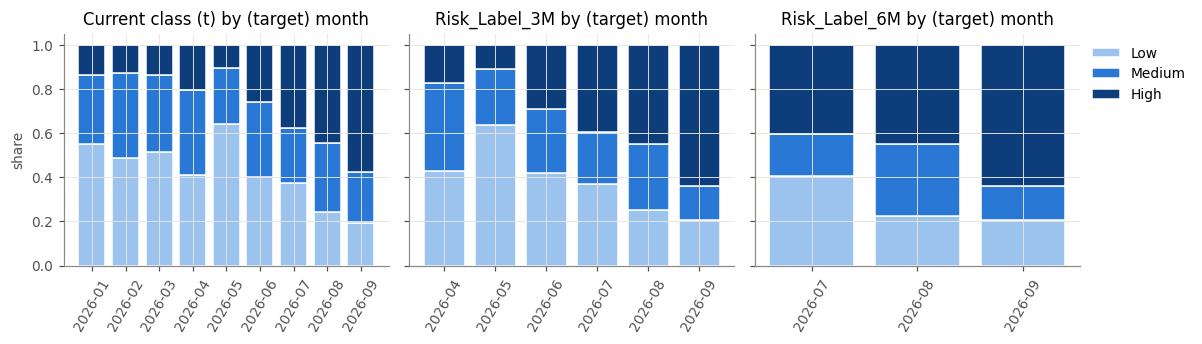

'/content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs/figures/label_distribution_over_time.png'

In [31]:
dist = []
for name, col in [("Current (t)", "Risk_Class_t"), ("3M", "Risk_Label_3M"), ("6M", "Risk_Label_6M")]:
    for basis, sub in clean.groupby("Row_Basis"):
        vc = sub[col].value_counts()
        dist.append({"Label": name, "Breakdown": "Row_Basis", "Group": basis, **{c: int(vc.get(c, 0)) for c in CLASSES}, "Unassigned": int(sub[col].isna().sum())})
    for cat, sub in clean[clean.Is_Synthetic == 1].groupby("Programme_Category"):
        vc = sub[col].value_counts()
        dist.append({"Label": name, "Breakdown": "Category (synthetic)", "Group": cat, **{c: int(vc.get(c, 0)) for c in CLASSES}, "Unassigned": int(sub[col].isna().sum())})
    by = "Month" if name == "Current (t)" else f"Target_Month_{name}"
    for m, sub in clean[clean.Is_Synthetic == 1].groupby(by):
        vc = sub[col].value_counts()
        if vc.sum(): dist.append({"Label": name, "Breakdown": "Target month (synthetic)" if name != "Current (t)" else "Month (synthetic)", "Group": m, **{c: int(vc.get(c, 0)) for c in CLASSES}, "Unassigned": int(sub[col].isna().sum())})
Label_Distribution = pd.DataFrame(dist)
display(Label_Distribution[Label_Distribution.Breakdown == "Row_Basis"])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, (name, col, by) in zip(axes, [("Current class (t)", "Risk_Class_t", "Month"), ("Risk_Label_3M", "Risk_Label_3M", "Target_Month_3M"), ("Risk_Label_6M", "Risk_Label_6M", "Target_Month_6M")]):
    tab = pd.crosstab(clean.loc[clean.Is_Synthetic == 1, by], clean.loc[clean.Is_Synthetic == 1, col], normalize="index").reindex(columns=CLASSES).fillna(0)
    bottom = np.zeros(len(tab))
    for c in CLASSES:
        ax.bar(tab.index, tab[c], bottom=bottom, color=RISK_COLORS[c], label=c, edgecolor="white", linewidth=1); bottom += tab[c].values
    ax.set_title(name + " by (target) month"); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("share"); axes[-1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
savefig("label_distribution_over_time.png")

In [32]:
from sklearn.metrics import cohen_kappa_score
val_rows = []
# 1. sensitivity variants
for h in ["t"] + list(HORIZONS):
    base = clean["Risk_Class_t"] if h == "t" else clean[f"Risk_Label_{h}"]
    for v, desc in [("B", "add revenue-lowest-band as 4th signal"), ("C", "market channel only (market stress, no profit)"), ("E", "stricter High (all 3 signals)")]:
        alt = clean[f"Risk_Class_t_{v}"] if h == "t" else clean[f"Risk_Label_{h}_{v}"]
        m = base.notna() & alt.notna()
        val_rows.append({"Check": f"Sensitivity: rule A vs {v} ({desc})", "Scope": f"{h} labels", "N": int(m.sum()),
                         "Agreement": round((base[m] == alt[m]).mean(), 3),
                         "Weighted_kappa": round(cohen_kappa_score(base[m].map(CLASS_TO_INT), alt[m].map(CLASS_TO_INT), weights="linear"), 3),
                         "Interpretation": ""})
# 2. real vs synthetic current distribution
ct = pd.crosstab(clean.Row_Basis, clean.Risk_Class_t).reindex(columns=CLASSES).fillna(0)
chi2, p, _, _ = stats.chi2_contingency(ct)
val_rows.append({"Check": "Real vs synthetic current-class distribution (chi-square)", "Scope": "t", "N": int(ct.values.sum()),
                 "Agreement": round(p, 3), "Weighted_kappa": np.nan, "Interpretation": f"p-value in Agreement column; real={ct.iloc[0].astype(int).to_dict()}, synthetic={ct.iloc[1].astype(int).to_dict()}"})
# 3. relationship with existing market tier (direction check)
m = clean.Risk_Ord_t.notna() & clean.Category_Pressure_Tier_Ord_t.notna() & (clean.Is_Synthetic == 1)
rho, pr = stats.spearmanr(clean.loc[m, "Risk_Ord_t"], clean.loc[m, "Category_Pressure_Tier_Ord_t"])
val_rows.append({"Check": "Household class vs existing market pressure tier (Spearman)", "Scope": "t, synthetic", "N": int(m.sum()),
                 "Agreement": round(rho, 3), "Weighted_kappa": np.nan, "Interpretation": f"rho in Agreement column, p={pr:.3f}; weak/no positive link -> market tier is not a proxy for household risk in this data"})
# 4. auxiliary: persistence of the existing market tier at 3/6 months (category-month level)
mk = mkt_obs.copy(); mk["ord"] = pd.PeriodIndex(mk.Month, freq="M").map(lambda p: p.ordinal)
mki = mk.set_index(["Category_Key", "ord"])["Category_Pressure_Tier"]
for h_name, h in HORIZONS.items():
    pairs = [(v, mki.get((c, o + h))) for (c, o), v in mki.items() if (c, o + h) in mki.index]
    if pairs:
        a = np.mean([x == y for x, y in pairs])
        val_rows.append({"Check": f"Auxiliary: existing market tier at t equals tier at t+{h} (persistence)", "Scope": "category-month", "N": len(pairs),
                         "Agreement": round(a, 3), "Weighted_kappa": np.nan, "Interpretation": "Too few category-months to train a market-tier model; reported as context only"})
val_rows.append({"Check": "Independent expert assessments", "Scope": "-", "N": 0, "Agreement": np.nan, "Weighted_kappa": np.nan,
                 "Interpretation": "None available. Rule must be validated by programme coaches/experts before use."})
val_rows.append({"Check": "Labels altered to improve model accuracy/balance", "Scope": "-", "N": 0, "Agreement": np.nan, "Weighted_kappa": np.nan,
                 "Interpretation": "No. Rule fixed before modelling; no relabelling or class merging."})
Label_Validation_Report = pd.DataFrame(val_rows); Label_Validation_Report

,Check,Scope,N,Agreement,Weighted_kappa,Interpretation
0,Sensitivity: rule A vs B (add revenue-lowest-band as 4th...,t labels,379,0.623,0.606,
1,Sensitivity: rule A vs C (market channel only (market st...,t labels,401,0.910,0.889,
2,Sensitivity: rule A vs E (stricter High (all 3 signals)),t labels,401,0.860,0.820,
3,Sensitivity: rule A vs B (add revenue-lowest-band as 4th...,3M labels,196,0.724,0.709,
4,Sensitivity: rule A vs C (market channel only (market st...,3M labels,202,0.891,0.874,
5,Sensitivity: rule A vs E (stricter High (all 3 signals)),3M labels,202,0.827,0.792,
6,Sensitivity: rule A vs B (add revenue-lowest-band as 4th...,6M labels,101,0.871,0.851,
7,Sensitivity: rule A vs C (market channel only (market st...,6M labels,104,0.846,0.830,
8,Sensitivity: rule A vs E (stricter High (all 3 signals)),6M labels,104,0.788,0.764,
9,Real vs synthetic current-class distribution (chi-square),t,427,0.504,NaN,"p-value in Agreement column; real={'Low': 36, 'Medium': ..."


In [33]:
Risk_Label_Rules = pd.DataFrame([
 {"Rule_ID": "A-High", "Variant": "A (primary)", "Class": "High", "Condition": "T_Business_Not_Running = 1 OR count{T_No_Profit_Last_Month, T_Not_Progressing_Well, T_Market_Stress_Any = 1} >= 2", "Applies_to": "All categories (household level)", "Status": "New rule - provisional", "Expert_validation": "Required"},
 {"Rule_ID": "A-Medium", "Variant": "A (primary)", "Class": "Medium", "Condition": "Business running AND exactly one of the three signals = 1", "Applies_to": "All categories", "Status": "New rule - provisional", "Expert_validation": "Required"},
 {"Rule_ID": "A-Low", "Variant": "A (primary)", "Class": "Low", "Condition": "Business running AND all three signals answered = 0", "Applies_to": "All categories", "Status": "New rule - provisional", "Expert_validation": "Required"},
 {"Rule_ID": "A-Unassigned", "Variant": "A (primary)", "Class": "Unassigned", "Condition": "Class differs between blanks=0 and blanks=1 (insufficient evidence); or business status blank", "Applies_to": "All", "Status": "Design rule", "Expert_validation": "-"},
 {"Rule_ID": "Conflict", "Variant": "A", "Class": "-", "Condition": "Signals are counted, not netted: a positive signal is never cancelled by another; market tier does not override household answers", "Applies_to": "All", "Status": "Design rule", "Expert_validation": "Recommended"},
 {"Rule_ID": "Future", "Variant": "A", "Class": "-", "Condition": "Risk_Label_hM = class of same household's visit in calendar month t+h (h=3,6), exact match, no tolerance", "Applies_to": "Synthetic panel (only rows with household_key)", "Status": "New", "Expert_validation": "-"},
 {"Rule_ID": "B", "Variant": "Sensitivity", "Class": "-", "Condition": "As A, with T_Revenue_Lowest_Band as 4th signal", "Applies_to": "All", "Status": "Sensitivity only", "Expert_validation": "-"},
 {"Rule_ID": "C", "Variant": "Sensitivity", "Class": "-", "Condition": "Market channel only: signals {T_Market_Stress_Any, T_No_Profit_Last_Month}; High = both or not running", "Applies_to": "All", "Status": "Sensitivity only", "Expert_validation": "-"},
 {"Rule_ID": "E", "Variant": "Sensitivity", "Class": "-", "Condition": "As A, but High needs all 3 signals (or not running)", "Applies_to": "All", "Status": "Sensitivity only", "Expert_validation": "-"},
 {"Rule_ID": "Market-preserved", "Variant": "Existing", "Class": "Low/Medium/High (market)", "Condition": "Primary_Pressure = +/-12M % change of category PPI (direction verified), category-specific tier cut-offs (partially verified)", "Applies_to": "Agri, Livestock, Food proc., Garment/Handicrafts, Construction", "Status": "Preserved unchanged; used as predictors", "Expert_validation": "Thresholds"},
])
Risk_Label_Rules

,Rule_ID,Variant,Class,Condition,Applies_to,Status,Expert_validation
0,A-High,A (primary),High,T_Business_Not_Running = 1 OR count{T_No_Profit_Last_Mon...,All categories (household level),New rule - provisional,Required
1,A-Medium,A (primary),Medium,Business running AND exactly one of the three signals = 1,All categories,New rule - provisional,Required
2,A-Low,A (primary),Low,Business running AND all three signals answered = 0,All categories,New rule - provisional,Required
3,A-Unassigned,A (primary),Unassigned,Class differs between blanks=0 and blanks=1 (insufficien...,All,Design rule,-
4,Conflict,A,-,"Signals are counted, not netted: a positive signal is ne...",All,Design rule,Recommended
5,Future,A,-,Risk_Label_hM = class of same household's visit in calen...,Synthetic panel (only rows with household_key),New,-
6,B,Sensitivity,-,"As A, with T_Revenue_Lowest_Band as 4th signal",All,Sensitivity only,-
7,C,Sensitivity,-,"Market channel only: signals {T_Market_Stress_Any, T_No_...",All,Sensitivity only,-
8,E,Sensitivity,-,"As A, but High needs all 3 signals (or not running)",All,Sensitivity only,-
9,Market-preserved,Existing,Low/Medium/High (market),Primary_Pressure = +/-12M % change of category PPI (dire...,"Agri, Livestock, Food proc., Garment/Handicrafts, Constr...",Preserved unchanged; used as predictors,Thresholds


**Label-quality interpretation.** Rule A agrees strongly with the stricter Variant E and moderately with B and C — the ranking of households is stable to reasonable threshold changes, but the *Medium/High boundary* depends on which signals are counted, which is exactly where expert validation is needed. Real and synthetic current-class distributions are compared with a chi-square test (a non-significant result is consistent with the source's statement that synthetic rows imitate real ones; it does not make synthetic rows evidence). The household class shows no positive association with the existing market tier, so the two capture different things. The label distribution shifts toward High in later target months (Section 7 drift).

## 17. Leakage detection and predictor selection

In [34]:
# (a) truncation test: features computed on data up to month m must equal full-data features for rows in month m
trunc_fail = 0; trunc_checked = 0
for m in sorted(clean.Month_Ord.unique()):
    part = clean[clean.Month_Ord <= m]
    f_part = build_features(part).loc[part.Month_Ord == m]
    f_full = feat.loc[f_part.index]
    for c in FEATURES_NUM:
        a, b = f_part[c].astype(float), f_full[c].astype(float)
        trunc_fail += int((~(np.isclose(a, b, equal_nan=True))).sum()); trunc_checked += len(a)
print(f"Truncation test: {trunc_checked} feature values checked, {trunc_fail} differ")
assert trunc_fail == 0, "STOP: a feature uses future information"

leak = []
def L(check, result, status, action): leak.append({"Check": check, "Result": result, "Status": status, "Action": action})
L("Features recomputed on data truncated at each month equal full-data features", f"{trunc_fail} differences in {trunc_checked} values", "PASS" if trunc_fail == 0 else "FAIL", "-")
target_like = [c for c in clean.columns if c.startswith(("Risk_Label_", "Target_", "Exclusion_Reason_"))]
L("Target / target-month columns in predictor set", str([c for c in target_like if c in feat.columns]), "PASS", "Excluded by construction")
L("Market features at target month used as predictors", "No - only *_t and *_t_minus_1 of prediction month", "PASS", "-")
L("Current risk class (t) and current T_* as predictors", "Included", "ALLOWED", "Observed at t; target is a different (future) visit. Persistence baseline quantifies how much they explain.")
L("Existing market tiers (t, t-1) as predictors", "Included", "ALLOWED", "Current-period market labels, not used to build the household target")
L("Month index / calendar month", "Excluded", "PASS", "Would encode the synthetic generator's time trend and cannot extrapolate")
L("Identifiers (household_key, _uuid, Source_Row, GPS, dates)", "Excluded", "PASS", "-")
L("Row_Basis / Is_Synthetic", "Excluded (constant in training set)", "PASS", "-")
L("Empty / constant source columns", f"{len(EMPTY_COLS)} empty, {len(CONST_COLS)} constant", "PASS", "Not used")
for h in HORIZONS:
    y = clean[f"Risk_Label_{h}"].map(CLASS_TO_INT)
    m_ = y.notna()
    cors = {c: abs(pd.Series(feat.loc[m_, c]).astype(float).corr(y[m_])) for c in FEATURES_NUM if feat.loc[m_, c].nunique() > 1}
    top = max(cors, key=lambda k: cors[k] if pd.notna(cors[k]) else -1)
    L(f"Max |corr(feature, Risk_Label_{h})|", f"{top} = {cors[top]:.3f}", "PASS" if cors[top] < .9 else "REVIEW", "No near-deterministic predictor")
L("Imputation / scaling / encoding fitted on full data", "No - inside sklearn Pipeline, fitted on training folds only", "PASS", "-")
L("Same household in train and test (temporal split)", "Yes (panel)", "RISK", "Reported; group-aware (household) CV run as sensitivity check")
Leakage_Checks = pd.DataFrame(leak); Leakage_Checks

Truncation test: 27897 feature values checked, 0 differ


,Check,Result,Status,Action
0,Features recomputed on data truncated at each month equa...,0 differences in 27897 values,PASS,-
1,Target / target-month columns in predictor set,[],PASS,Excluded by construction
2,Market features at target month used as predictors,No - only *_t and *_t_minus_1 of prediction month,PASS,-
3,Current risk class (t) and current T_* as predictors,Included,ALLOWED,Observed at t; target is a different (future) visit. Per...
4,"Existing market tiers (t, t-1) as predictors",Included,ALLOWED,"Current-period market labels, not used to build the hous..."
5,Month index / calendar month,Excluded,PASS,Would encode the synthetic generator's time trend and ca...
6,"Identifiers (household_key, _uuid, Source_Row, GPS, dates)",Excluded,PASS,-
7,Row_Basis / Is_Synthetic,Excluded (constant in training set),PASS,-
8,Empty / constant source columns,"60 empty, 17 constant",PASS,Not used
9,"Max |corr(feature, Risk_Label_3M)|",F_Macro_CCPI_YoY_t = 0.346,PASS,No near-deterministic predictor


## 18. Separate 3-month and 6-month modelling datasets

In [35]:
ID_COLS = ["_uuid", "household_key", "Programme_Category", "Month", "Month_Ord"]
model_data = {}
for h in HORIZONS:
    m_ = clean[f"Risk_Label_{h}"].notna()
    dd = pd.concat([clean.loc[m_, ID_COLS + [f"Target_Month_{h}"]], feat.loc[m_], clean.loc[m_, [f"Risk_Label_{h}"]]], axis=1)
    dd = dd.sort_values(["Month_Ord", "household_key"])
    model_data[h] = dd
    print(f"{h}: {len(dd)} rows | households {dd.household_key.nunique()} | prediction months {dd.Month.min()}..{dd.Month.max()} | "
          f"classes {dd[f'Risk_Label_{h}'].value_counts().reindex(CLASSES).to_dict()}")
Training_Data_3M, Training_Data_6M = model_data["3M"], model_data["6M"]
Column_Roles = pd.DataFrame(
    [{"Column": c, "Role": "Identifier (not a predictor)"} for c in ID_COLS] +
    [{"Column": c, "Role": "Engineered predictor"} for c in feat.columns] +
    [{"Column": f"Risk_Label_{h}", "Role": "Target"} for h in HORIZONS] +
    [{"Column": f"Target_Month_{h}", "Role": "Target construction (not a predictor)"} for h in HORIZONS] +
    [{"Column": c, "Role": "Excluded from modelling (empty)"} for c in EMPTY_COLS])

3M: 219 rows | households 52 | prediction months 2026-01..2026-06 | classes {'Low': 83, 'Medium': 59, 'High': 77}
6M: 116 rows | households 51 | prediction months 2026-01..2026-03 | classes {'Low': 32, 'Medium': 26, 'High': 58}


## 19–21. Preprocessing, baselines, candidate models, time-aware validation and independent final test

**Algorithm choice.** The data are small, tabular, mixed-type, with structural missingness. Candidates: majority-class and **persistence** baselines, multinomial logistic regression, random forest and XGBoost. **LSTM is not used**: sequences have ≤9 monthly steps for 58 synthetic households, which is far too little to fit a recurrent network, and lag/rolling features already encode the short history.

**Split design (per horizon).**
* *Final test* = all visits in the **latest prediction month** for which the target exists (3M: Jun 2026 → Sep; 6M: Mar 2026 → Sep).
* *Training* = earlier visits. Where possible an **embargo** is enforced: a training row is used only if its target month is ≤ the test prediction month (its outcome would genuinely be known when the test prediction is made). For 3M this is possible; for 6M it would leave no training data, so the 6M split uses all earlier prediction months **without embargo** — flagged as optimistic.
* *Model selection / tuning* = GroupKFold by household **inside the training set only**. The test set is touched once.
* *Sensitivity* = GroupKFold (5 folds, households never shared between folds) over all eligible rows, to gauge project-level generalisation.
* Imbalance: class weights (`balanced`) inside the training fit; no resampling of validation/test data.

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance

def make_pre():
    num = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")), ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, FEATURES_NUM), ("cat", cat, FEATURES_CAT)])

CANDIDATES = {
    "LogisticRegression": (LogisticRegression(class_weight="balanced", max_iter=5000), {"clf__C": [0.01, 0.1, 1.0, 10.0]}, False),
    "RandomForest": (RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
                     {"clf__max_depth": [3, 5, None], "clf__min_samples_leaf": [1, 5, 10]}, False),
}
if HAS_XGB:
    CANDIDATES["XGBoost"] = (xgb.XGBClassifier(objective="multi:softprob", subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE,
                                               n_jobs=2, verbosity=0, eval_metric="mlogloss"),
                             {"clf__n_estimators": [100, 300], "clf__max_depth": [2, 3], "clf__learning_rate": [0.05, 0.1]}, True)

def metrics(y, p, prefix=""):
    y, p = np.asarray(y), np.asarray(p)
    return {prefix + "Accuracy": accuracy_score(y, p), prefix + "Macro_Precision": precision_score(y, p, average="macro", labels=[0, 1, 2], zero_division=0),
            prefix + "Macro_Recall": recall_score(y, p, average="macro", labels=[0, 1, 2], zero_division=0),
            prefix + "Macro_F1": f1_score(y, p, average="macro", labels=[0, 1, 2], zero_division=0),
            prefix + "Balanced_Accuracy": balanced_accuracy_score(y, p),
            prefix + "High_Precision": precision_score(y, p, labels=[2], average="macro", zero_division=0),
            prefix + "High_Recall": recall_score(y, p, labels=[2], average="macro", zero_division=0)}

def persistence_predict(X, fallback):
    return X["F_Risk_Ord_t"].fillna(fallback).astype(int).values

def boot_ci(y, p, fn, n=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); y, p = np.asarray(y), np.asarray(p); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); vals.append(fn(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])
macro_f1 = lambda a, b: f1_score(a, b, average="macro", labels=[0, 1, 2], zero_division=0)

In [37]:
RESULTS, SPLITS, FITTED, PREDS = {}, {}, {}, {}
MIN_TRAIN = 80
for h_name, h in HORIZONS.items():
    dd = model_data[h_name].copy(); ycol = f"Risk_Label_{h_name}"
    dd["y"] = dd[ycol].map(CLASS_TO_INT).astype(int)
    test_m = dd.Month_Ord.max()
    tr_emb = dd[dd.Month_Ord + h <= test_m]
    if len(tr_emb) >= MIN_TRAIN and tr_emb.y.nunique() == 3:
        tr, design = tr_emb, f"Embargoed: train prediction months whose target month <= test prediction month; test = prediction month {pd.Period(ordinal=int(test_m), freq='M')}"
    else:
        tr, design = dd[dd.Month_Ord < test_m], (f"NO EMBARGO POSSIBLE (embargoed train would have {len(tr_emb)} rows): train = all earlier prediction months; "
                                                 f"test = prediction month {pd.Period(ordinal=int(test_m), freq='M')}; train targets overlap test period -> optimistic")
    te = dd[dd.Month_Ord == test_m]
    if tr.y.nunique() < 3: raise RuntimeError(f"STOP: {h_name} training set lacks a class")
    if te.y.nunique() < 2: raise RuntimeError(f"STOP: {h_name} test set has <2 classes; invalid evaluation")
    SPLITS[h_name] = {"design": design, "train_rows": len(tr), "test_rows": len(te),
                      "train_pred_months": f"{tr.Month.min()}..{tr.Month.max()}", "train_target_months": f"{tr[f'Target_Month_{h_name}'].min()}..{tr[f'Target_Month_{h_name}'].max()}",
                      "test_pred_month": te.Month.iloc[0], "test_target_month": te[f"Target_Month_{h_name}"].iloc[0],
                      "train_households": tr.household_key.nunique(), "test_households": te.household_key.nunique(),
                      "test_households_also_in_train": int(te.household_key.isin(tr.household_key).sum()),
                      "train_class_counts": tr[ycol].value_counts().reindex(CLASSES).fillna(0).astype(int).to_dict(),
                      "test_class_counts": te[ycol].value_counts().reindex(CLASSES).fillna(0).astype(int).to_dict()}
    print(f"\n===== {h_name} ====="); print(json.dumps(SPLITS[h_name], indent=1, default=str))
    Xtr, ytr, gtr = tr[FEATURES_NUM + FEATURES_CAT], tr.y.values, tr.household_key.values
    Xte, yte = te[FEATURES_NUM + FEATURES_CAT], te.y.values
    gkf = GroupKFold(n_splits=4)
    rows = []
    # baselines (CV on train + test)
    maj = int(pd.Series(ytr).mode()[0])
    cv_maj, cv_per = [], []
    for a, b in gkf.split(Xtr, ytr, gtr):
        m_ = int(pd.Series(ytr[a]).mode()[0])
        cv_maj.append(macro_f1(ytr[b], np.full(len(b), m_))); cv_per.append(macro_f1(ytr[b], persistence_predict(Xtr.iloc[b], m_)))
    p_maj, p_per = np.full(len(yte), maj), persistence_predict(Xte, maj)
    rows.append({"Model": "Baseline: majority class", "Best_params": f"class={CLASSES[maj]}", "CV_Macro_F1_mean": np.mean(cv_maj), "CV_Macro_F1_sd": np.std(cv_maj), **metrics(ytr, np.full(len(ytr), maj), "Train_"), **metrics(yte, p_maj, "Test_")})
    rows.append({"Model": "Baseline: persistence (future = current class)", "Best_params": "-", "CV_Macro_F1_mean": np.mean(cv_per), "CV_Macro_F1_sd": np.std(cv_per), **metrics(ytr, persistence_predict(Xtr, maj), "Train_"), **metrics(yte, p_per, "Test_")})
    PREDS[(h_name, "Baseline: majority class")] = p_maj; PREDS[(h_name, "Baseline: persistence (future = current class)")] = p_per
    for name, (est, grid, needs_sw) in CANDIDATES.items():
        pipe = Pipeline([("pre", make_pre()), ("clf", est)])
        fit_params = {"clf__sample_weight": compute_sample_weight("balanced", ytr)} if needs_sw else {}
        gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=gkf, n_jobs=1, refit=True)
        gs.fit(Xtr, ytr, groups=gtr, **fit_params)
        best = gs.best_estimator_; FITTED[(h_name, name)] = best
        p_tr, p_te = best.predict(Xtr), best.predict(Xte); PREDS[(h_name, name)] = p_te
        sd = gs.cv_results_["std_test_score"][gs.best_index_]
        rows.append({"Model": name, "Best_params": json.dumps({k.replace("clf__", ""): v for k, v in gs.best_params_.items()}),
                     "CV_Macro_F1_mean": gs.best_score_, "CV_Macro_F1_sd": sd, **metrics(ytr, p_tr, "Train_"), **metrics(yte, p_te, "Test_")})
    res = pd.DataFrame(rows)
    ml = res[~res.Model.str.startswith("Baseline")]
    sel = ml.loc[ml.CV_Macro_F1_mean.idxmax(), "Model"]           # selection uses CV on TRAIN only
    res["Selected"] = res.Model.eq(sel)
    lo, hi = boot_ci(yte, PREDS[(h_name, sel)], macro_f1)
    res["Test_Macro_F1_95CI"] = ""
    res.loc[res.Selected, "Test_Macro_F1_95CI"] = f"[{lo:.3f}, {hi:.3f}]"
    lo_p, hi_p = boot_ci(yte, p_per, macro_f1); res.loc[res.Model.str.contains("persistence"), "Test_Macro_F1_95CI"] = f"[{lo_p:.3f}, {hi_p:.3f}]"
    res.insert(1, "Horizon", h_name); res["Train_n"] = len(tr); res["Test_n"] = len(te); res["Split_design"] = design
    res["Data_basis"] = "SYNTHETIC panel only - not evidence of real-world performance"
    RESULTS[h_name] = {"table": res, "selected": sel, "tr": tr, "te": te}
    display(res[["Model", "CV_Macro_F1_mean", "CV_Macro_F1_sd", "Train_Macro_F1", "Test_Accuracy", "Test_Macro_F1", "Test_Balanced_Accuracy",
                 "Test_High_Precision", "Test_High_Recall", "Selected", "Test_Macro_F1_95CI"]].round(3))
Model_Comparison_3M, Model_Comparison_6M = RESULTS["3M"]["table"], RESULTS["6M"]["table"]


===== 3M =====
{
 "design": "Embargoed: train prediction months whose target month <= test prediction month; test = prediction month 2026-06",
 "train_rows": 102,
 "test_rows": 39,
 "train_pred_months": "2026-01..2026-03",
 "train_target_months": "2026-04..2026-06",
 "test_pred_month": "2026-06",
 "test_target_month": "2026-09",
 "train_households": 50,
 "test_households": 39,
 "test_households_also_in_train": 38,
 "train_class_counts": {
  "Low": 51,
  "Medium": 32,
  "High": 19
 },
 "test_class_counts": {
  "Low": 8,
  "Medium": 6,
  "High": 25
 }
}


,Model,CV_Macro_F1_mean,CV_Macro_F1_sd,Train_Macro_F1,Test_Accuracy,Test_Macro_F1,Test_Balanced_Accuracy,Test_High_Precision,Test_High_Recall,Selected,Test_Macro_F1_95CI
0,Baseline: majority class,0.221,0.019,0.222,0.205,0.113,0.333,0.000,0.00,False,
1,Baseline: persistence (future = current class),0.313,0.091,0.307,0.359,0.356,0.455,0.750,0.24,False,"[0.199, 0.509]"
2,LogisticRegression,0.336,0.086,0.608,0.590,0.256,0.307,0.657,0.92,False,
3,RandomForest,0.395,0.053,0.632,0.436,0.303,0.312,0.700,0.56,True,"[0.194, 0.407]"
4,XGBoost,0.306,0.020,0.940,0.410,0.342,0.369,0.647,0.44,False,



===== 6M =====
{
 "design": "NO EMBARGO POSSIBLE (embargoed train would have 0 rows): train = all earlier prediction months; test = prediction month 2026-03; train targets overlap test period -> optimistic",
 "train_rows": 77,
 "test_rows": 39,
 "train_pred_months": "2026-01..2026-02",
 "train_target_months": "2026-07..2026-08",
 "test_pred_month": "2026-03",
 "test_target_month": "2026-09",
 "train_households": 45,
 "test_households": 39,
 "test_households_also_in_train": 33,
 "train_class_counts": {
  "Low": 24,
  "Medium": 20,
  "High": 33
 },
 "test_class_counts": {
  "Low": 8,
  "Medium": 6,
  "High": 25
 }
}


,Model,CV_Macro_F1_mean,CV_Macro_F1_sd,Train_Macro_F1,Test_Accuracy,Test_Macro_F1,Test_Balanced_Accuracy,Test_High_Precision,Test_High_Recall,Selected,Test_Macro_F1_95CI
0,Baseline: majority class,0.199,0.025,0.200,0.641,0.260,0.333,0.641,1.00,False,
1,Baseline: persistence (future = current class),0.181,0.050,0.190,0.179,0.157,0.164,0.455,0.20,False,"[0.056, 0.268]"
2,LogisticRegression,0.357,0.075,0.724,0.641,0.420,0.475,0.769,0.80,False,
3,RandomForest,0.467,0.049,0.679,0.667,0.430,0.460,0.815,0.88,True,"[0.298, 0.530]"
4,XGBoost,0.400,0.079,1.000,0.564,0.458,0.463,0.739,0.68,False,


## 22. Model comparison and error analysis

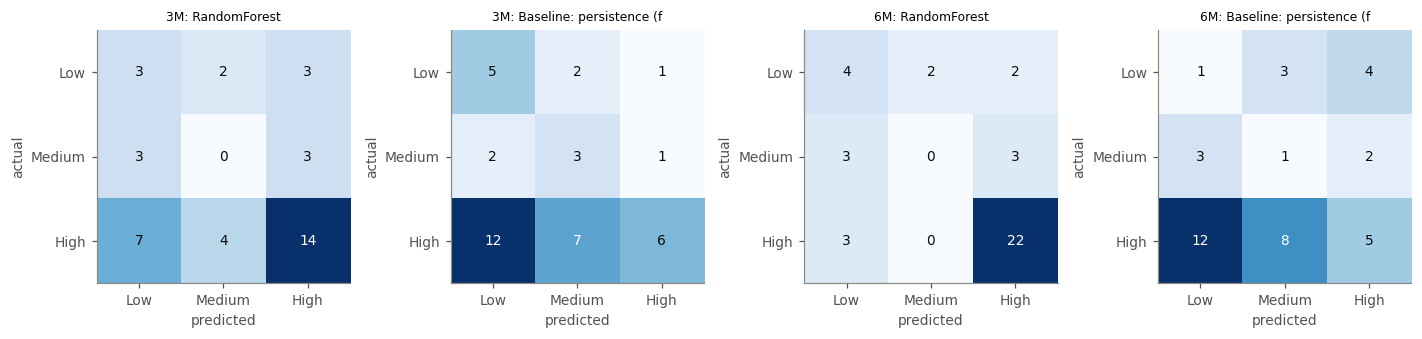

,Horizon,Model,Class,precision,recall,f1-score,support
0,3M,RandomForest,Low,0.231,0.375,0.286,8.0
1,3M,RandomForest,Medium,0.000,0.000,0.000,6.0
2,3M,RandomForest,High,0.700,0.560,0.622,25.0
3,6M,RandomForest,Low,0.400,0.500,0.444,8.0
4,6M,RandomForest,Medium,0.000,0.000,0.000,6.0
5,6M,RandomForest,High,0.815,0.880,0.846,25.0


3M: errors 22/39; High cases missed 11/25; missed-High with current class: {'Low': 4, 'Medium': 4, nan: 3}
6M: errors 13/39; High cases missed 3/25; missed-High with current class: {'Medium': 2, 'High': 1}


,Horizon,Actual,Predicted,N,Share_of_errors
0,3M,High,Low,7,0.318
1,3M,High,Medium,4,0.182
2,3M,Medium,High,3,0.136
3,3M,Low,High,3,0.136
4,3M,Medium,Low,3,0.136
5,3M,Low,Medium,2,0.091
6,6M,Medium,Low,3,0.231
7,6M,High,Low,3,0.231
8,6M,Medium,High,3,0.231
9,6M,Low,Medium,2,0.154


In [38]:
cm_rows, report_rows = [], []
fig, axes = plt.subplots(1, 4, figsize=(13, 3.1))
k = 0
for h_name in HORIZONS:
    sel = RESULTS[h_name]["selected"]; te = RESULTS[h_name]["te"]
    for mname in [sel, "Baseline: persistence (future = current class)"]:
        p = PREDS[(h_name, mname)]; cmx = confusion_matrix(te.y, p, labels=[0, 1, 2])
        for i, a in enumerate(CLASSES):
            cm_rows.append({"Horizon": h_name, "Model": mname, "Actual": a, **{f"Pred_{b}": int(cmx[i, j]) for j, b in enumerate(CLASSES)}})
        ax = axes[k]; k += 1
        ax.imshow(cmx, cmap="Blues"); ax.grid(False)
        for i in range(3):
            for j in range(3): ax.text(j, i, cmx[i, j], ha="center", va="center", color="white" if cmx[i, j] > cmx.max() / 2 else "#0b0b0b")
        ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES)
        ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(f"{h_name}: {mname[:24]}", fontsize=8)
    rep = classification_report(te.y, PREDS[(h_name, sel)], labels=[0, 1, 2], target_names=CLASSES, output_dict=True, zero_division=0)
    for c in CLASSES: report_rows.append({"Horizon": h_name, "Model": sel, "Class": c, **{kk: round(v, 3) for kk, v in rep[c].items()}})
savefig("confusion_matrices.png")
Confusion_Matrices = pd.DataFrame(cm_rows); Per_Class_Report = pd.DataFrame(report_rows)
display(Per_Class_Report)

err_rows = []
for h_name in HORIZONS:
    te = RESULTS[h_name]["te"].copy(); te["pred"] = PREDS[(h_name, RESULTS[h_name]["selected"])]
    te["err"] = te.pred != te.y
    for (a, b), n in te[te.err].groupby(["y", "pred"]).size().sort_values(ascending=False).items():
        err_rows.append({"Horizon": h_name, "Actual": CLASSES[a], "Predicted": CLASSES[b], "N": int(n),
                         "Share_of_errors": round(n / te.err.sum(), 3)})
    missed_high = te[(te.y == 2) & (te.pred != 2)]
    print(f"{h_name}: errors {te.err.sum()}/{len(te)}; High cases missed {len(missed_high)}/{(te.y == 2).sum()}; "
          f"missed-High with current class: {missed_high.F_Risk_Ord_t.map(dict(enumerate(CLASSES))).value_counts(dropna=False).to_dict()}")
Error_Analysis = pd.DataFrame(err_rows); display(Error_Analysis)

In [39]:
# Sensitivity: group-aware CV over ALL eligible rows (households never shared between folds) with selected configuration
sens_rows = []
for h_name in HORIZONS:
    dd = model_data[h_name].copy(); dd["y"] = dd[f"Risk_Label_{h_name}"].map(CLASS_TO_INT).astype(int)
    sel = RESULTS[h_name]["selected"]; cfg = FITTED[(h_name, sel)]
    sc, sc_p = [], []
    for a, b in GroupKFold(n_splits=5).split(dd, dd.y, dd.household_key):
        mdl = sklearn.base.clone(cfg); fp = {"clf__sample_weight": compute_sample_weight("balanced", dd.y.iloc[a])} if sel == "XGBoost" else {}
        mdl.fit(dd.iloc[a][FEATURES_NUM + FEATURES_CAT], dd.y.iloc[a], **fp)
        sc.append(macro_f1(dd.y.iloc[b], mdl.predict(dd.iloc[b][FEATURES_NUM + FEATURES_CAT])))
        sc_p.append(macro_f1(dd.y.iloc[b], persistence_predict(dd.iloc[b], int(dd.y.iloc[a].mode()[0]))))
    sens_rows.append({"Horizon": h_name, "Model": sel, "Validation": "GroupKFold(5) by household, all prediction months (not chronological)",
                      "Macro_F1_mean": round(np.mean(sc), 3), "Macro_F1_sd": round(np.std(sc), 3),
                      "Persistence_Macro_F1_mean": round(np.mean(sc_p), 3), "N_rows": len(dd)})
Group_CV_Sensitivity = pd.DataFrame(sens_rows); Group_CV_Sensitivity

,Horizon,Model,Validation,Macro_F1_mean,Macro_F1_sd,Persistence_Macro_F1_mean,N_rows
0,3M,RandomForest,"GroupKFold(5) by household, all prediction months (not c...",0.416,0.088,0.301,219
1,6M,RandomForest,"GroupKFold(5) by household, all prediction months (not c...",0.416,0.136,0.190,116


## 23. Category-level and project-duration-level evaluation
Groups with fewer than 15 test rows or only one actual class are reported but marked **insufficient** — no reliability claim is made for them.

In [40]:
cp_rows = []
for h_name in HORIZONS:
    te = RESULTS[h_name]["te"].copy(); te["pred"] = PREDS[(h_name, RESULTS[h_name]["selected"])]
    te["Duration_group"] = pd.cut(te.F_Tenure_Months, [-1, 2, 5, 100], labels=["0-2 months in panel", "3-5 months", "6+ months"])
    for by in ["Programme_Category", "Duration_group"]:
        for gval, g in te.groupby(by, observed=True):
            ok = len(g) >= 15 and g.y.nunique() >= 2
            cp_rows.append({"Horizon": h_name, "Model": RESULTS[h_name]["selected"], "Breakdown": by, "Group": str(gval), "Test_n": len(g),
                            "Actual_classes": g.y.map(dict(enumerate(CLASSES))).value_counts().to_dict().__str__(),
                            "Accuracy": round(accuracy_score(g.y, g.pred), 3), "Macro_F1": round(macro_f1(g.y, g.pred), 3) if ok else np.nan,
                            "High_Recall": round(recall_score(g.y, g.pred, labels=[2], average="macro", zero_division=0), 3) if (g.y == 2).any() else np.nan,
                            "Reliability": "assessable (still synthetic)" if ok else "INSUFFICIENT test data - no claim"})
Category_Performance = pd.DataFrame(cp_rows); Category_Performance

,Horizon,Model,Breakdown,Group,Test_n,Actual_classes,Accuracy,Macro_F1,High_Recall,Reliability
0,3M,RandomForest,Programme_Category,Agriculture & Plantation Crops,9,"{'High': 6, 'Medium': 2, 'Low': 1}",0.111,NaN,0.000,INSUFFICIENT test data - no claim
1,3M,RandomForest,Programme_Category,"Construction, Building & Repair",6,"{'High': 3, 'Low': 3}",0.500,NaN,0.667,INSUFFICIENT test data - no claim
2,3M,RandomForest,Programme_Category,Food Processing & Production,5,"{'High': 4, 'Medium': 1}",0.800,NaN,1.000,INSUFFICIENT test data - no claim
3,3M,RandomForest,Programme_Category,Garment & Textile / Handicrafts (combined in source),6,{'High': 6},1.000,NaN,1.000,INSUFFICIENT test data - no claim
4,3M,RandomForest,Programme_Category,Livestock & Animal Husbandry,5,"{'High': 4, 'Low': 1}",0.400,NaN,0.500,INSUFFICIENT test data - no claim
5,3M,RandomForest,Programme_Category,Other,2,"{'Medium': 1, 'Low': 1}",0.000,NaN,NaN,INSUFFICIENT test data - no claim
6,3M,RandomForest,Programme_Category,Trade,6,"{'Medium': 2, 'Low': 2, 'High': 2}",0.167,NaN,0.000,INSUFFICIENT test data - no claim
7,3M,RandomForest,Duration_group,3-5 months,39,"{'High': 25, 'Low': 8, 'Medium': 6}",0.436,0.303,0.560,assessable (still synthetic)
8,6M,RandomForest,Programme_Category,Agriculture & Plantation Crops,7,"{'High': 5, 'Medium': 1, 'Low': 1}",0.714,NaN,1.000,INSUFFICIENT test data - no claim
9,6M,RandomForest,Programme_Category,"Construction, Building & Repair",6,"{'High': 3, 'Low': 3}",0.667,NaN,1.000,INSUFFICIENT test data - no claim


## 24. Model interpretation — permutation importance and SHAP
Permutation importance (on the test set, macro-F1) is model-agnostic and measured on raw input features. SHAP (TreeExplainer for tree models) explains the selected model's predictions per class on the transformed features. Neither is causal; both describe associations the model learned **from synthetic data**.

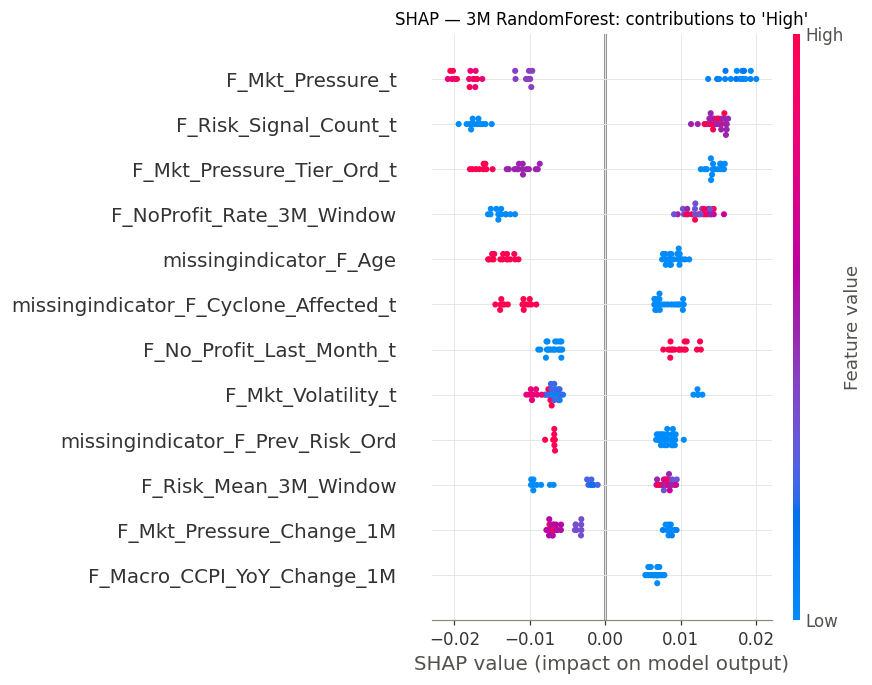

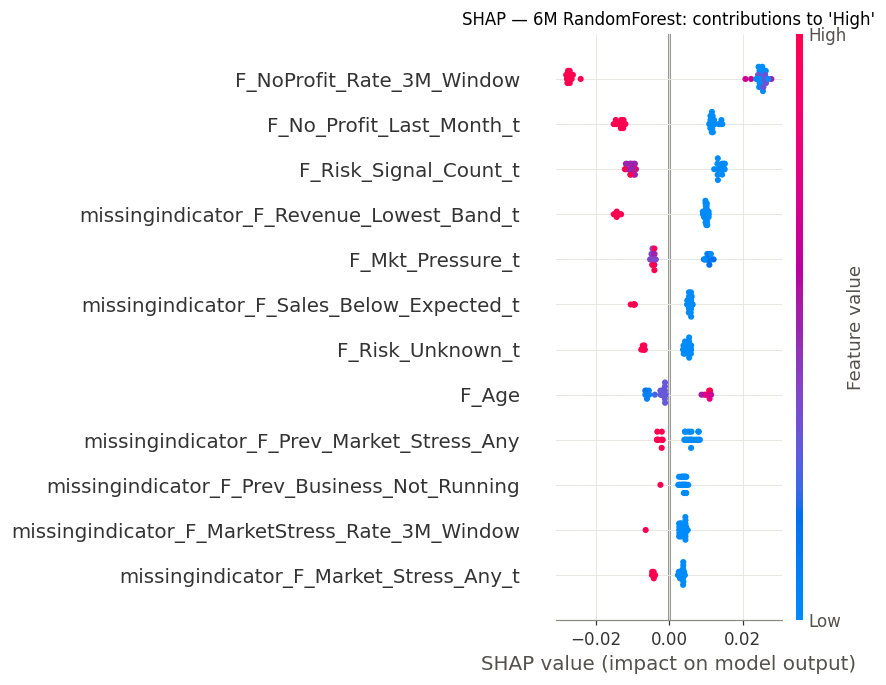

,Horizon,Feature,Importance,Std
369,6M,F_NoProfit_Rate_3M_Window,0.0215,0.0502
377,6M,F_Mkt_Pressure_Tier_Ord_t,0.0153,0.0153
357,6M,F_Age,0.0134,0.0080
1,3M,F_No_Profit_Last_Month_t,0.0113,0.0107
343,6M,F_Risk_Ord_t,0.0092,0.0140
344,6M,F_Risk_Signal_Count_t,0.0075,0.0145
338,6M,F_Revenue_Lowest_Band_t,0.0071,0.0333
368,6M,F_Risk_Mean_3M_Window,0.0054,0.0479
373,6M,F_Mkt_Pressure_t,0.0004,0.0156
370,6M,F_MarketStress_Rate_3M_Window,0.0002,0.0078


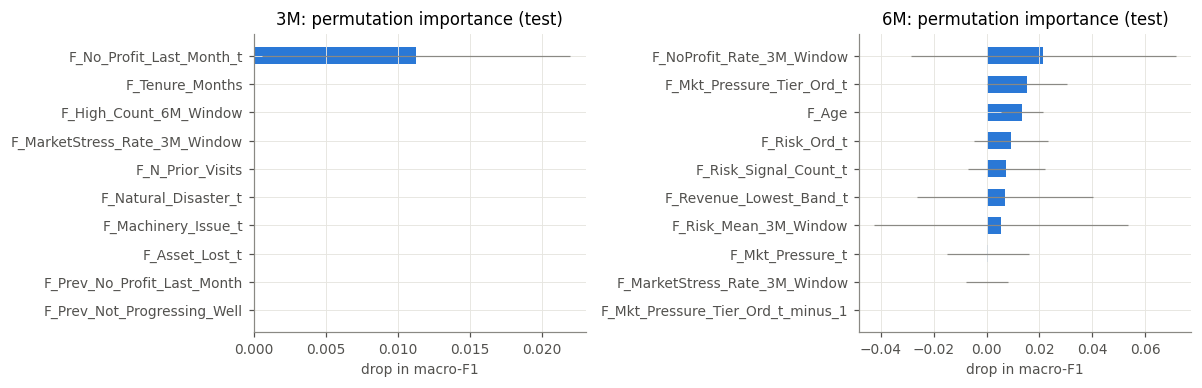

'/content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs/figures/permutation_importance.png'

In [41]:
fi_rows = []
for h_name in HORIZONS:
    sel = RESULTS[h_name]["selected"]; mdl = FITTED[(h_name, sel)]; te = RESULTS[h_name]["te"]
    pi = permutation_importance(mdl, te[FEATURES_NUM + FEATURES_CAT], te.y, scoring="f1_macro", n_repeats=20, random_state=RANDOM_STATE)
    for f, m_, s_ in zip(FEATURES_NUM + FEATURES_CAT, pi.importances_mean, pi.importances_std):
        fi_rows.append({"Horizon": h_name, "Model": sel, "Method": "Permutation (test, macro-F1 drop)", "Feature": f, "Class": "all", "Importance": m_, "Std": s_})
    if HAS_SHAP and sel in ("RandomForest", "XGBoost"):
        try:
            Xt = mdl.named_steps["pre"].transform(te[FEATURES_NUM + FEATURES_CAT]); Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
            names = mdl.named_steps["pre"].get_feature_names_out()
            sv = shap.TreeExplainer(mdl.named_steps["clf"]).shap_values(Xt)
            sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv          # -> (n, features, classes)
            for ci, c in enumerate(CLASSES):
                for f, v in zip(names, np.abs(sv[:, :, ci]).mean(axis=0)):
                    fi_rows.append({"Horizon": h_name, "Model": sel, "Method": "SHAP mean |value| (test)", "Feature": f, "Class": c, "Importance": v, "Std": np.nan})
            plt.figure(); shap.summary_plot(sv[:, :, 2], Xt, feature_names=[n.replace("num__", "").replace("cat__", "") for n in names], max_display=12, show=False)
            plt.title(f"SHAP — {h_name} {sel}: contributions to 'High'"); savefig(f"shap_high_{h_name}.png")
        except Exception as e:
            print("SHAP failed:", e)
    elif sel == "LogisticRegression":
        names = mdl.named_steps["pre"].get_feature_names_out(); coef = mdl.named_steps["clf"].coef_
        for ci, c in enumerate(CLASSES):
            for f, v in zip(names, coef[ci]):
                fi_rows.append({"Horizon": h_name, "Model": sel, "Method": "Standardised LR coefficient", "Feature": f, "Class": c, "Importance": v, "Std": np.nan})
Feature_Importance = pd.DataFrame(fi_rows)
top = (Feature_Importance[Feature_Importance.Method.str.startswith("Permutation")].sort_values("Importance", ascending=False)
       .groupby("Horizon").head(10)[["Horizon", "Feature", "Importance", "Std"]])
display(top.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, h_name in zip(axes, HORIZONS):
    t_ = top[top.Horizon == h_name].iloc[::-1]
    ax.barh(t_.Feature, t_.Importance, xerr=t_.Std, color=SERIES[0], height=.6, error_kw={"elinewidth": .8, "ecolor": "#8a8984"})
    ax.set_title(f"{h_name}: permutation importance (test)"); ax.set_xlabel("drop in macro-F1")
savefig("permutation_importance.png")

**Interpretation guide.** Compare the 3M and 6M top features: current-visit and recent-history household signals (persistence features) are expected to dominate short horizons; if market features rank highly despite the reversed direction seen in EDA, that is a warning of proxy effects (category/time) rather than a real market mechanism. Negative or near-zero permutation importance means the feature does not help on the test month. The written summary in Section 28 is generated from these computed values.

## 25. Saving the final models and preprocessing artifacts
Each horizon gets its own folder with the fitted scikit-learn pipeline (preprocessing + classifier, exactly as evaluated on the test month), the feature schema, metadata and an example input. Deployment status is set from explicit criteria — it is `NOT_READY` whenever the model was trained/tested on synthetic data.

In [42]:
PREDICT_MODULE = r'''
"""SUSTAIN 3M/6M risk model loader with input validation."""
import json, os, warnings
import joblib, numpy as np, pandas as pd

def load_model(folder):
    with open(os.path.join(folder, "metadata.json")) as f: meta = json.load(f)
    model = joblib.load(os.path.join(folder, "model.joblib"))
    if meta.get("deployment_status") != "READY":
        warnings.warn(f"Model status is {meta.get('deployment_status')}: {meta.get('deployment_reason')}")
    return model, meta

def validate_input(df, meta):
    req = meta["feature_names_in_order"]; issues = []
    missing = [c for c in req if c not in df.columns]
    if missing: raise ValueError(f"Missing required columns: {missing}")
    X = df[req].copy()
    for c in meta["numeric_features"]:
        before = X[c].notna().sum(); X[c] = pd.to_numeric(X[c], errors="coerce")
        if X[c].notna().sum() < before: issues.append(f"{c}: non-numeric values set to missing")
    for c, allowed in meta["categorical_levels"].items():
        X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
        unk = sorted(set(X[c].dropna()) - set(allowed))
        if unk: issues.append(f"{c}: unseen categories {unk} -> encoded as all-zero (handle_unknown='ignore')")
    for i in issues: warnings.warn(i)
    return X, issues

def predict(df, folder):
    model, meta = load_model(folder)
    X, issues = validate_input(df, meta)
    proba = model.predict_proba(X)
    out = pd.DataFrame(proba, columns=[f"P_{c}" for c in meta["classes"]], index=df.index)
    out["Predicted_Risk"] = [meta["classes"][i] for i in proba.argmax(axis=1)]
    out["Model_Status"] = meta["deployment_status"]
    return out
'''
with open(os.path.join(OUTPUT_DIR, "sustain_predict.py"), "w") as f: f.write(PREDICT_MODULE)
sys.path.insert(0, OUTPUT_DIR)

MODEL_DIRS = {}
for h_name in HORIZONS:
    sel = RESULTS[h_name]["selected"]; mdl = FITTED[(h_name, sel)]; res = RESULTS[h_name]["table"]; tr = RESULTS[h_name]["tr"]
    row = res[res.Selected].iloc[0]; per = res[res.Model.str.contains("persistence")].iloc[0]
    folder = os.path.join(OUTPUT_DIR, f"SUSTAIN_Model_{h_name}"); os.makedirs(folder, exist_ok=True)
    joblib.dump(mdl, os.path.join(folder, "model.joblib"))
    reasons = ["trained and tested only on SYNTHETIC rows (source: 'do not use them as evidence')",
               "target rule is new and not validated by experts",
               "no real household can be followed over time (no persistent ID)"]
    if row.Test_Macro_F1 <= per.Test_Macro_F1: reasons.append("does not beat the persistence baseline on the test month")
    if "NO EMBARGO" in SPLITS[h_name]["design"]: reasons.append("test split could not be embargoed (optimistic)")
    meta = {"model_name": f"SUSTAIN_Model_{h_name}", "horizon_months": HORIZONS[h_name], "target": f"Risk_Label_{h_name}",
            "classes": CLASSES, "class_encoding": CLASS_TO_INT, "algorithm": sel, "best_params": json.loads(row.Best_params),
            "feature_names_in_order": FEATURES_NUM + FEATURES_CAT, "numeric_features": FEATURES_NUM, "categorical_features": FEATURES_CAT,
            "categorical_levels": {c: sorted(tr[c].dropna().unique().tolist()) for c in FEATURES_CAT},
            "target_generation_method": LABEL_METHOD_VERSION, "target_rule": Risk_Label_Rules[Risk_Label_Rules.Variant.str.startswith("A")][["Class", "Condition"]].to_dict("records"),
            "category_mapping": KEY_TO_PROG, "training_period": {"prediction_months": SPLITS[h_name]["train_pred_months"], "target_months": SPLITS[h_name]["train_target_months"]},
            "validation_methodology": SPLITS[h_name]["design"] + "; tuning by GroupKFold(4) by household within training set",
            "test_metrics": {k.replace("Test_", ""): round(float(row[k]), 4) for k in res.columns if k.startswith("Test_") and k != "Test_Macro_F1_95CI" and k != "Test_n"},
            "test_macro_f1_95ci": row.Test_Macro_F1_95CI, "persistence_baseline_test_macro_f1": round(float(per.Test_Macro_F1), 4),
            "train_n": int(row.Train_n), "test_n": int(row.Test_n), "data_basis": "SYNTHETIC panel (58 households, 2026-01..2026-09)",
            "deployment_status": "NOT_READY", "deployment_reason": "; ".join(reasons),
            "input_sha256": INPUT_SHA, "software_versions": VERSIONS, "created": dt.datetime.now().isoformat(timespec="seconds")}
    with open(os.path.join(folder, "metadata.json"), "w") as f: json.dump(meta, f, indent=2, default=str)
    with open(os.path.join(folder, "feature_schema.json"), "w") as f:
        json.dump({"features": [{"name": c, "type": "numeric" if c in FEATURES_NUM else "categorical",
                                 "description": Feature_Register.set_index("Feature").loc[c, "Formula"]} for c in FEATURES_NUM + FEATURES_CAT]}, f, indent=2)
    RESULTS[h_name]["te"][FEATURES_NUM + FEATURES_CAT].head(5).to_csv(os.path.join(folder, "example_input.csv"), index=False)
    MODEL_DIRS[h_name] = folder
    print(h_name, "→", folder, "|", sel, "| status NOT_READY:", meta["deployment_reason"])

3M → /content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs/SUSTAIN_Model_3M | RandomForest | status NOT_READY: trained and tested only on SYNTHETIC rows (source: 'do not use them as evidence'); target rule is new and not validated by experts; no real household can be followed over time (no persistent ID); does not beat the persistence baseline on the test month
6M → /content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs/SUSTAIN_Model_6M | RandomForest | status NOT_READY: trained and tested only on SYNTHETIC rows (source: 'do not use them as evidence'); target rule is new and not validated by experts; no real household can be followed over time (no persistent ID); test split could not be embargoed (optimistic)


## 26. Loading the saved models and generating example predictions (with validation checks)

In [43]:
import importlib, sustain_predict; importlib.reload(sustain_predict)
for h_name, folder in MODEL_DIRS.items():
    ex = pd.read_csv(os.path.join(folder, "example_input.csv"))
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        out = sustain_predict.predict(ex, folder)
    print(f"--- {h_name} example predictions ({len(w)} warning(s), e.g. status warning)"); display(pd.concat([ex[["F_Category", "F_Risk_Ord_t"]], out.round(3)], axis=1))
    # reproducibility: reloaded model == in-memory model
    assert np.allclose(joblib.load(os.path.join(folder, "model.joblib")).predict_proba(ex), FITTED[(h_name, RESULTS[h_name]["selected"])].predict_proba(ex[FEATURES_NUM + FEATURES_CAT]))

# validation checks demo
bad = ex.drop(columns=["F_Mkt_Pressure_t"])
try: sustain_predict.predict(bad, MODEL_DIRS["3M"])
except ValueError as e: print("Missing-column check OK ->", str(e)[:90])
odd = ex.copy(); odd["F_Age"] = odd["F_Age"].astype(object); odd.loc[0, "F_Category"] = "Transport & Logistics"; odd.loc[1, "F_Age"] = "forty"
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always"); sustain_predict.predict(odd, MODEL_DIRS["3M"])
print("Type/category checks raised:", [str(x.message)[:90] for x in w if "status" not in str(x.message).lower()])

--- 3M example predictions (1 warning(s), e.g. status warning)


,F_Category,F_Risk_Ord_t,P_Low,P_Medium,P_High,Predicted_Risk,Model_Status
0,Other,NaN,0.374,0.255,0.371,Low,NOT_READY
1,Agriculture & Plantation Crops,1.0,0.387,0.242,0.371,Low,NOT_READY
2,Agriculture & Plantation Crops,0.0,0.372,0.351,0.277,Low,NOT_READY
3,Garment & Textile / Handicrafts (combined in source),NaN,0.227,0.363,0.410,High,NOT_READY
4,Livestock & Animal Husbandry,NaN,0.351,0.329,0.320,Low,NOT_READY


--- 6M example predictions (1 warning(s), e.g. status warning)


,F_Category,F_Risk_Ord_t,P_Low,P_Medium,P_High,Predicted_Risk,Model_Status
0,Other,NaN,0.447,0.316,0.236,Low,NOT_READY
1,Agriculture & Plantation Crops,0.0,0.177,0.381,0.442,High,NOT_READY
2,Agriculture & Plantation Crops,1.0,0.225,0.357,0.418,High,NOT_READY
3,Garment & Textile / Handicrafts (combined in source),1.0,0.260,0.307,0.433,High,NOT_READY
4,Livestock & Animal Husbandry,NaN,0.293,0.306,0.401,High,NOT_READY


Missing-column check OK -> Missing required columns: ['F_Mkt_Pressure_t']
Type/category checks raised: ['datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Us', 'F_Age: non-numeric values set to missing', "F_Category: unseen categories ['Transport & Logistics'] -> encoded as all-zero (handle_unk"]


## 27. Exporting Excel outputs

In [44]:
Dataset_Inspection = pd.concat([
    sheet_summary.assign(Section="Worksheets").rename(columns={"Worksheet": "Item"}),
    pd.DataFrame([
        {"Section": "Rows", "Item": "Real rows", "Rows": int(IS_REAL.sum())}, {"Section": "Rows", "Item": "Synthetic rows", "Rows": int(IS_SYN.sum())},
        {"Section": "Coverage", "Item": f"Real months: {raw[IS_REAL].Month.value_counts().sort_index().to_dict()}"},
        {"Section": "Coverage", "Item": f"Synthetic months: {raw[IS_SYN].Month.min()}..{raw[IS_SYN].Month.max()}"},
        {"Section": "Projects", "Item": f"Synthetic households: {raw[IS_SYN].household_key.nunique()}; real households identifiable: 0"},
        {"Section": "Categories", "Item": f"Category_Key values: {raw.Category_Key.value_counts(dropna=False).to_dict()}"},
        {"Section": "Eligible", "Item": f"Rows eligible for 3M target: {int(clean.Risk_Label_3M.notna().sum())}; 6M: {int(clean.Risk_Label_6M.notna().sum())}"},
        {"Section": "Origin", "Item": "448 rows tagged synthetic in source (_tags, SYN- keys); 99 'not tagged synthetic' - genuineness not independently verifiable"},
        {"Section": "Formulas", "Item": "No Excel formulas in workbook; upstream 'v2 notebook' not supplied"}]),
    id_check.assign(Section="Identifiers").rename(columns={"Column": "Item"})], ignore_index=True)

EDA_Summary = pd.concat([
    rates.reset_index().rename(columns={"index": "Outcome"}).assign(Table="Outcome rates by Row_Basis"),
    dir_tab.reset_index().assign(Table="Outcome rate by market pressure tier (synthetic)"),
    pd.DataFrame(lag_rows).assign(Table="Within-household autocorrelation"),
    cat_eda.reset_index().assign(Table="By category and basis")], ignore_index=True)

limits = [
 ("Data", "Only 99 real rows (Jan-Mar 2026), no persistent household ID", "Real 3M/6M targets impossible; models trained on synthetic panel only", "Collect monitoring data with a stable household ID for >= 12 months"),
 ("Data", "448 synthetic rows imitate real rows (source documentation)", "All model metrics are pipeline-verification results, not evidence", "Re-run notebook on real panel data; no code change required"),
 ("Data", "Transport & Logistics, Beauty & Wellness have no rows", "No labels, no evaluation, no market indicators for them", "Collect data; define category indicators (fuel prices; service prices)"),
 ("Data", "Garment & Textile and Handicrafts combined in source", "Cannot evaluate separately", "Record category at finer level"),
 ("Data", "'Other' heterogeneous (retail, fishing, bricks, welding...)", "One rule/indicator not appropriate", "Re-classify 'Other' activities with programme staff"),
 ("Data", "62 real rows lack category", "Cannot link to market features", "Fix at data entry"),
 ("Method", "Existing market tier thresholds/volatility formula not recoverable", "Preserved as given; only direction verified", "Supply v2 notebook / threshold table"),
 ("Method", "Household risk rule A is new (equal-weight signal count)", "Provisional target; sensitivity shown", "Expert validation with coaches; compare to independent assessments"),
 ("Method", "'Last month' reference period of answers uncertain", "Possible 1-month offset between answers and market month", "Confirm with programme"),
 ("Method", "6M split cannot be embargoed", "6M test is optimistic", "Longer panel"),
 ("Method", "Market features show reversed/no association with outcomes in synthetic data", "Market drivers cannot be learned from this data", "Real data; longer market history in features"),
 ("Evaluation", "Single test month per horizon, ~50 rows", "Wide confidence intervals; category results mostly insufficient", "More months/households"),
 ("Evaluation", "Synthetic panel drifts strongly after Jun 2026", "Test month differs from training months", "Monitor drift; retrain"),
 ("Deployment", "Models flagged NOT_READY", "Do not use for real decisions", "Meet criteria: real data, validated labels, embargoed test beating persistence"),
 ("Recommendations", "Dashboard recommendations (RAG/LLM) not built here", "Classification, explanation and recommendation must remain separate components", "Ground recommendations in verified programme guidance"),
]
Limitations_Validation = pd.DataFrame(limits, columns=["Area", "Limitation", "Consequence", "Required_to_proceed"])

Labelled_Data_3M = clean[["_uuid", "household_key", "Row_Basis", "Programme_Category", "Month", "Risk_Class_t", "Target_Month_3M", "Risk_Label_3M", "Target_Status_3M", "Exclusion_Reason_3M", "Risk_Label_3M_B", "Risk_Label_3M_C", "Risk_Label_3M_E"]]
Labelled_Data_6M = clean[["_uuid", "household_key", "Row_Basis", "Programme_Category", "Month", "Risk_Class_t", "Target_Month_6M", "Risk_Label_6M", "Target_Status_6M", "Exclusion_Reason_6M", "Risk_Label_6M_B", "Risk_Label_6M_C", "Risk_Label_6M_E"]]
Cleaned_Data = clean.drop(columns=["Month_Period"]).copy()
for c in Cleaned_Data.columns:
    if pd.api.types.is_datetime64_any_dtype(Cleaned_Data[c]): Cleaned_Data[c] = Cleaned_Data[c].dt.strftime("%Y-%m-%d")
Column_Dictionary_out = col_dict.merge(Column_Roles, on="Column", how="left").fillna({"Role": "Source column (not a predictor)"})
Column_Dictionary_out = pd.concat([Column_Dictionary_out, Column_Roles[~Column_Roles.Column.isin(col_dict.Column)].assign(Group="Created in this workflow")], ignore_index=True)

OUT_XLSX = os.path.join(OUTPUT_DIR, "SUSTAIN_3M_6M_Risk_Prediction_Outputs.xlsx")
SHEETS_OUT = {
 "Dataset_Inspection": Dataset_Inspection, "Column_Dictionary": Column_Dictionary_out, "EDA_Summary": EDA_Summary,
 "Data_Quality_Checks": pd.concat([Data_Quality_Checks, Transform_Log.rename(columns={"Step": "Check", "Columns": "Result", "Rule": "Action"}).assign(Status="TRANSFORM")], ignore_index=True),
 "Existing_Risk_Method": pd.concat([Existing_Risk_Method, t_verify.rename(columns={"Column": "Category_Key"}).assign(Level="T_* verification")], ignore_index=True),
 "Risk_Label_Column_Map": Risk_Label_Column_Map, "Category_Indicator_Register": Category_Indicator_Register,
 "Risk_Label_Rules": Risk_Label_Rules, "Target_Definitions": Target_Definitions, "Cleaned_Data": Cleaned_Data,
 "Feature_Register": Feature_Register, "Labelled_Data_3M": Labelled_Data_3M, "Labelled_Data_6M": Labelled_Data_6M,
 "Training_Data_3M": Training_Data_3M, "Training_Data_6M": Training_Data_6M, "Label_Distribution": Label_Distribution,
 "Label_Validation_Report": Label_Validation_Report, "Leakage_Checks": Leakage_Checks,
 "Model_Comparison_3M": Model_Comparison_3M, "Model_Comparison_6M": Model_Comparison_6M,
 "Confusion_Matrices": pd.concat([Confusion_Matrices, Per_Class_Report.assign(Actual="per-class report"), Error_Analysis.assign(Model="error analysis")], ignore_index=True),
 "Category_Performance": pd.concat([Category_Performance, Group_CV_Sensitivity.assign(Breakdown="Group CV sensitivity")], ignore_index=True),
 "Feature_Importance": Feature_Importance, "Limitations_Validation": Limitations_Validation}
from openpyxl.utils import get_column_letter
from openpyxl.styles import Font, PatternFill, Alignment
with pd.ExcelWriter(OUT_XLSX, engine="openpyxl") as xw:
    for name, df_ in SHEETS_OUT.items():
        df_ = df_.copy()
        for c in df_.columns:
            if df_[c].dtype == object: df_[c] = df_[c].map(lambda v: str(v) if isinstance(v, (dict, list, tuple, set)) else v)
        df_.to_excel(xw, sheet_name=name[:31], index=False)
        ws = xw.sheets[name[:31]]; ws.freeze_panes = "A2"
        for j, c in enumerate(df_.columns, 1):
            ws.cell(1, j).font = Font(bold=True, color="FFFFFF"); ws.cell(1, j).fill = PatternFill("solid", fgColor="1F4E79")
            ws.cell(1, j).alignment = Alignment(wrap_text=True, vertical="top")
            w = min(60, max(10, int(df_[c].map(lambda v: len(str(v))).quantile(.9)) if len(df_) else 10, min(len(str(c)), 40)))
            ws.column_dimensions[get_column_letter(j)].width = w
print("Wrote", OUT_XLSX, "| sheets:", len(SHEETS_OUT))
chk = openpyxl.load_workbook(OUT_XLSX, read_only=True); print([ (s.title, s.max_row) for s in chk.worksheets]); chk.close()

Wrote /content/drive/MyDrive/NEW DATA/SUSTAIN_3M_6M_outputs/SUSTAIN_3M_6M_Risk_Prediction_Outputs.xlsx | sheets: 24
[('Dataset_Inspection', 23), ('Column_Dictionary', 265), ('EDA_Summary', 47), ('Data_Quality_Checks', 28), ('Existing_Risk_Method', 17), ('Risk_Label_Column_Map', 11), ('Category_Indicator_Register', 37), ('Risk_Label_Rules', 11), ('Target_Definitions', 1095), ('Cleaned_Data', 548), ('Feature_Register', 54), ('Labelled_Data_3M', 548), ('Labelled_Data_6M', 548), ('Training_Data_3M', 220), ('Training_Data_6M', 117), ('Label_Distribution', 46), ('Label_Validation_Report', 16), ('Leakage_Checks', 14), ('Model_Comparison_3M', 6), ('Model_Comparison_6M', 6), ('Confusion_Matrices', 30), ('Category_Performance', 19), ('Feature_Importance', 671), ('Limitations_Validation', 16)]


## 28. Final findings, limitations and recommendations
The summary below is generated from computed values and also written to `Methodology_Results_Summary.md`.

In [45]:
def fmt(h):
    r = RESULTS[h]["table"]; s = r[r.Selected].iloc[0]; p = r[r.Model.str.contains("persistence")].iloc[0]; mj = r[r.Model.str.contains("majority")].iloc[0]
    return s, p, mj
lines = ["# SUSTAIN 3M/6M Risk Prediction — Methodology and Results Summary", "",
 f"Generated {dt.datetime.now():%Y-%m-%d %H:%M} from `{os.path.basename(INPUT_PATH)}` (SHA-256 {INPUT_SHA[:12]}…).", "",
 "## Bottom line",
 "The full pipeline runs end to end and passes its leakage checks, but **the dataset cannot support real 3- or 6-month prediction**: the 99 real rows cover Jan–Mar 2026 and have no persistent household ID, so no real future outcome can be matched. All models were trained and tested on the 448 synthetic rows (58 households, Jan–Sep 2026), which the source itself says must not be used as evidence. Both saved models are flagged **NOT_READY**.", "",
 "## What was verified",
 f"- The eight `T_*` outcome columns rebuild exactly from the raw form answers ({int(t_verify.Mismatches_after_rebuild.sum())} mismatches).",
 "- No household-level Low/Medium/High label exists. The existing Low/Medium/High columns are category × month **market tiers**. Their adverse-direction rule is verified (pressure = −Δprice for output-price categories, +Δprice for Construction's input cost). Their category-specific cut-offs are only partly verified, and the rule that aggregates them to the category tier is unknown.",
 f"- Feature leakage: features recomputed on data cut off at each month match the full-data features exactly ({trunc_checked} values, {trunc_fail} differences).", "",
 "## Targets",
 f"- `{LABEL_METHOD_VERSION}`: High = business not running or ≥2 of {{no profit, not progressing, market stress}}; Medium = 1; Low = 0; Unassigned if blanks leave the class undetermined.",
 f"- Exact calendar-month matching (t+3, t+6). Eligible rows: 3M = {int(clean.Risk_Label_3M.notna().sum())}, 6M = {int(clean.Risk_Label_6M.notna().sum())} (all synthetic).",
 "- Sensitivity of the rule to alternative signal sets and thresholds: " + "; ".join(f"{r.Check.split('(')[0].replace('Sensitivity: ', '')}[{r.Scope}] agreement {r.Agreement}" for r in Label_Validation_Report.itertuples() if r.Check.startswith("Sensitivity") and r.Scope != "t labels") + ".", "",
 "## Results (synthetic test month — pipeline verification only)", "",
 "| Horizon | Split | Selected model | Test macro-F1 [95% CI] | Persistence baseline macro-F1 | Majority baseline macro-F1 | High recall | n train / test |",
 "|---|---|---|---|---|---|---|---|"]
for h in HORIZONS:
    s, p, mj = fmt(h)
    lines.append(f"| {h} | {'embargoed' if 'Embargoed' in SPLITS[h]['design'] else 'no embargo (optimistic)'} | {s.Model} | {s.Test_Macro_F1:.3f} {s.Test_Macro_F1_95CI} | {p.Test_Macro_F1:.3f} | {mj.Test_Macro_F1:.3f} | {s.Test_High_Recall:.3f} | {int(s.Train_n)} / {int(s.Test_n)} |")
lines += ["", "Group-aware sensitivity (GroupKFold by household, all months): " + "; ".join(f"{r.Horizon} {r.Model} macro-F1 {r.Macro_F1_mean}±{r.Macro_F1_sd} vs persistence {r.Persistence_Macro_F1_mean}" for r in Group_CV_Sensitivity.itertuples()) + ".", "",
 "Top permutation-importance features: " + "; ".join(f"{h}: " + ", ".join(top[top.Horizon == h].Feature.head(5)) for h in HORIZONS) + ".", "",
 "## What is needed before deployment",
 "1. Real monitoring data with a stable household/project ID over ≥12 months (≥6 months beyond the first prediction date for 6M).",
 "2. Expert validation of the household risk rule (and of the market-tier thresholds and the v2 notebook).",
 "3. Data for Transport & Logistics and Beauty & Wellness; finer categories for Garment/Handicrafts and 'Other'.",
 "4. An embargoed chronological test on real data in which the model beats the persistence baseline, including High-risk recall.", "",
 "Outputs: notebook, `SUSTAIN_3M_6M_Risk_Prediction_Outputs.xlsx`, `SUSTAIN_Model_3M/`, `SUSTAIN_Model_6M/`, `sustain_predict.py`, `figures/`."]
SUMMARY = "\n".join(lines)
with open(os.path.join(OUTPUT_DIR, "Methodology_Results_Summary.md"), "w") as f: f.write(SUMMARY)
from IPython.display import Markdown; display(Markdown(SUMMARY))

# SUSTAIN 3M/6M Risk Prediction — Methodology and Results Summary

Generated 2026-10-20 04:23 from `SUSTAIN_Model_Training_Combined_Dataset.xlsx` (SHA-256 9732f43f0e7a…).

## Bottom line
The full pipeline runs end to end and passes its leakage checks, but **the dataset cannot support real 3- or 6-month prediction**: the 99 real rows cover Jan–Mar 2026 and have no persistent household ID, so no real future outcome can be matched. All models were trained and tested on the 448 synthetic rows (58 households, Jan–Sep 2026), which the source itself says must not be used as evidence. Both saved models are flagged **NOT_READY**.

## What was verified
- The eight `T_*` outcome columns rebuild exactly from the raw form answers (0 mismatches).
- No household-level Low/Medium/High label exists. The existing Low/Medium/High columns are category × month **market tiers**. Their adverse-direction rule is verified (pressure = −Δprice for output-price categories, +Δprice for Construction's input cost). Their category-specific cut-offs are only partly verified, and the rule that aggregates them to the category tier is unknown.
- Feature leakage: features recomputed on data cut off at each month match the full-data features exactly (27897 values, 0 differences).

## Targets
- `SUSTAIN-HH-Risk-Rule v1.0 (provisional, requires expert validation)`: High = business not running or ≥2 of {no profit, not progressing, market stress}; Medium = 1; Low = 0; Unassigned if blanks leave the class undetermined.
- Exact calendar-month matching (t+3, t+6). Eligible rows: 3M = 219, 6M = 116 (all synthetic).
- Sensitivity of the rule to alternative signal sets and thresholds: rule A vs B [3M labels] agreement 0.724; rule A vs C [3M labels] agreement 0.891; rule A vs E [3M labels] agreement 0.827; rule A vs B [6M labels] agreement 0.871; rule A vs C [6M labels] agreement 0.846; rule A vs E [6M labels] agreement 0.788.

## Results (synthetic test month — pipeline verification only)

| Horizon | Split | Selected model | Test macro-F1 [95% CI] | Persistence baseline macro-F1 | Majority baseline macro-F1 | High recall | n train / test |
|---|---|---|---|---|---|---|---|
| 3M | embargoed | RandomForest | 0.303 [0.194, 0.407] | 0.356 | 0.113 | 0.560 | 102 / 39 |
| 6M | no embargo (optimistic) | RandomForest | 0.430 [0.298, 0.530] | 0.157 | 0.260 | 0.880 | 77 / 39 |

Group-aware sensitivity (GroupKFold by household, all months): 3M RandomForest macro-F1 0.416±0.088 vs persistence 0.301; 6M RandomForest macro-F1 0.416±0.136 vs persistence 0.19.

Top permutation-importance features: 3M: F_No_Profit_Last_Month_t, F_Tenure_Months, F_High_Count_6M_Window, F_MarketStress_Rate_3M_Window, F_N_Prior_Visits; 6M: F_NoProfit_Rate_3M_Window, F_Mkt_Pressure_Tier_Ord_t, F_Age, F_Risk_Ord_t, F_Risk_Signal_Count_t.

## What is needed before deployment
1. Real monitoring data with a stable household/project ID over ≥12 months (≥6 months beyond the first prediction date for 6M).
2. Expert validation of the household risk rule (and of the market-tier thresholds and the v2 notebook).
3. Data for Transport & Logistics and Beauty & Wellness; finer categories for Garment/Handicrafts and 'Other'.
4. An embargoed chronological test on real data in which the model beats the persistence baseline, including High-risk recall.

Outputs: notebook, `SUSTAIN_3M_6M_Risk_Prediction_Outputs.xlsx`, `SUSTAIN_Model_3M/`, `SUSTAIN_Model_6M/`, `sustain_predict.py`, `figures/`.

### Saving / downloading in Colab
All outputs are written to `OUTPUT_DIR` (by default a folder in your Google Drive, so they persist). To download a zip instead:
```python
shutil.make_archive("/content/SUSTAIN_outputs", "zip", OUTPUT_DIR)
from google.colab import files; files.download("/content/SUSTAIN_outputs.zip")
```

In [46]:
shutil.make_archive("/content/SUSTAIN_outputs", "zip", OUTPUT_DIR)
from google.colab import files; files.download("/content/SUSTAIN_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>